# Milestone 2, Role 2: merge and analysis on the merged data

**Trans-Boundary Smog Prediction: Crop Fires and Climate Traps across Punjab (Pakistan and India)**
Munir Tariq (10067), Ismail Nooruddin (09958), Bilal Ayub (09716)

This notebook does Part 2A (merge, led by Person B) and Part 2B (analysis on the merged data) of the work plan.
It reads only the three cleaned Role 1 outputs in `Dataset/clean/`:

| Stream | File | Made by |
|---|---|---|
| Air quality | `aq_daily.parquet`, `aq_params.json` | `air_quality.ipynb` (Person A) |
| Weather and wind | `wx_daily.parquet` | `weather.ipynb` (Person B) |
| Fire | `fire_daily.parquet`, `fire_daily_long.parquet` | `fire.ipynb` (Person C) |

**Run order:** `air_quality.ipynb`, `weather.ipynb`, `fire.ipynb`, then this notebook (Kernel, Restart and Run All), from the repository root.

**Outputs:** `Dataset/clean/master_daily.parquet` (the master analytical dataset), `Dataset/clean/master_data_dictionary.csv`,
`Dataset/clean/role2_params.json` (everything chosen on the training period), `figures/fig_m*.png` and the report tables in `docs/tables/`,
and the submission workbook `Dataset/clean/Milestone2_Final_Master_and_EDA.xlsx` (master table first, then helper tables, Role 1 final tables and all EDA tables).

**Rules used everywhere below.** Train = 2022-08-04 to 2023-08-31, skip = 2023-09-01 to 2023-09-03, validation = 2023-09-04 to 2023-12-31.
Every choice (fire cone and radius, weather-trap cut-offs, scaling) is made on the training period only. The validation period is
only described, and 2024 is never read (it is kept for the Week 14 out-of-time test).

In [1]:
# ------------------------------------------------------------
# Setup: imports, paths and settings (all paths are set here, in one place)
# ------------------------------------------------------------
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D

ROOT = Path.cwd()                          # run from the repository root
sys.path.append(str(ROOT))

from src import config as C                # shared rules: cities, dates, folders
from src import merge as M                 # Part 2A functions (all take a date window)
from src import eda as E                   # Part 2B helper functions
from src import plotting as P              # one figure style for every figure

P.set_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

START, END = C.WINDOW_START, C.WINDOW_END  # modelling window (AQ data starts 2022-08-04)
TABLE_DIR = ROOT / "docs" / "tables"       # tables quoted in the manuscript
TABLE_DIR.mkdir(parents=True, exist_ok=True)

def save_table(df, name):
    # keep every report table as CSV so the manuscript quotes exactly these numbers
    df.to_csv(TABLE_DIR / f"{name}.csv")
    return df

print("Window:", START, "to", END)
print("Train:", C.TRAIN_START, "to", C.TRAIN_END, "| skip:", C.SKIP_START, "to", C.SKIP_END,
      "| validation:", C.VALID_START, "to", C.VALID_END)

Window: 2022-08-04 to 2023-12-31
Train: 2022-08-04 to 2023-08-31 | skip: 2023-09-01 to 2023-09-03 | validation: 2023-09-04 to 2023-12-31


---
# Part 2A: Merge (Person B leads, A and C check)

## 2A.1 Swap and check

Each stream is loaded with the same function style and checked against the shared rules before anything is joined:
key columns present, the same 11 city spellings as `src/config.py`, the right country code, no duplicate city-day,
a complete calendar inside the window, and real date types.

**Change from the work plan, agreed by the team:** Air quality has no values before 2022-08-04 in any file, and imputing
about 210 days of pollution (6 January to 3 August 2022) would be invented data. All three streams are therefore cut to the modelling window
2022-08-04 to 2023-12-31 before the merge. Weather and fire keep three extra days before the window, used only to compute their 1 to 3 day lags.

In [2]:
# Load the three Role 1 outputs, cut to the window (weather and fire keep a 3-day lead-in for their lags)
aq = M.load_aq(START, END)
wx = M.load_weather(START, END, lead_in_days=3)
fire = M.load_fire_wide(START, END, lead_in_days=3)
aq_params = M.load_aq_params()

# Swap-and-check table: one row per stream, every rule must pass (the function raises if not)
swap_check = pd.DataFrame([M.check_keys(aq, "AQ (Person A)", START, END),
                           M.check_keys(wx, "Weather (Person B)", START, END),
                           M.check_keys(fire, "Fire (Person C)", START, END)]).set_index("table")
print(swap_check.T.to_string())

table                     AQ (Person A) Weather (Person B) Fire (Person C)
rows_in_window                     5665               5665            5665
key_columns_present                True               True            True
cities                               11                 11              11
city_names_match_config            True               True            True
country_matches_config             True               True            True
duplicate_city_date                   0                  0               0
first_date                   2022-08-04         2022-08-04      2022-08-04
last_date                    2023-12-31         2023-12-31      2023-12-31
full_calendar                      True               True            True
date_dtype               datetime64[ns]     datetime64[ns]  datetime64[ns]
city_dtype                          str                str             str


In [3]:
# Extra check found during the swap: Islamabad and Rawalpindi have identical AQ values on every day
# (the two cities are about 15 km apart and fall in the same air-quality model grid cell)
isb = aq[aq["city"] == "Islamabad"].set_index("date")["composite_smog_index"]
rwp = aq[aq["city"] == "Rawalpindi"].set_index("date")["composite_smog_index"]
print("Islamabad and Rawalpindi AQ identical on every day:", bool((isb == rwp).all()))
print("Independent AQ series: 10 (both cities are kept; their weather and fire columns differ)")

# The fire table's 'stagnant' column is a copy of Person B's flag. Confirm before dropping it in the loader
fire_raw = pd.read_parquet(C.CLEAN_DIR / "fire_daily.parquet")[["city", "date", "stagnant"]]
chk = wx[["city", "date", "stagnant"]].merge(M.normalise_keys(fire_raw.assign(country="x")).drop(columns="country"),
                                             on=["city", "date"], suffixes=("_wx", "_fire"))
print("Fire 'stagnant' equals weather 'stagnant' on every shared day:", bool((chk["stagnant_wx"] == chk["stagnant_fire"]).all()))

Islamabad and Rawalpindi AQ identical on every day: True
Independent AQ series: 10 (both cities are kept; their weather and fire columns differ)
Fire 'stagnant' equals weather 'stagnant' on every shared day: True


## 2A.2 Build the spine

The spine is an empty table with every city and every date of the window, built from the city list and a calendar, not from one of the data tables,
so a missing day in any stream would stay visible as a missing value after the join.

In [4]:
spine = M.build_spine(START, END)
n_days = (pd.Timestamp(END) - pd.Timestamp(START)).days + 1
print(f"Spine: {len(spine):,} rows = {spine['city'].nunique()} cities x {n_days} days")
assert len(spine) == 11 * n_days == 5665
spine.head(3)

Spine: 5,665 rows = 11 cities x 515 days


,city,country,date
0,Lahore,PK,2022-08-04
1,Lahore,PK,2022-08-05
2,Lahore,PK,2022-08-06


## 2A.3 Match key types

A join on keys of different types (for example text dates, or `datetime64[us]` against `datetime64[ns]`) silently matches nothing.
`normalise_keys` gives all tables the same types: `city` and `country` as clean text, `date` as `datetime64[ns]` at midnight local time (UTC+5).

In [5]:
key_types = pd.DataFrame({name: t[M.KEYS].dtypes.astype(str)
                          for name, t in [("spine", spine), ("AQ", aq), ("weather", wx), ("fire", fire)]})
print(key_types)
assert key_types.nunique(axis=1).eq(1).all(), "key types differ between tables"

                  spine              AQ         weather            fire
city                str             str             str             str
country             str             str             str             str
date     datetime64[ns]  datetime64[ns]  datetime64[ns]  datetime64[ns]


## 2A.4 Lags of weather and fire, then join one table at a time

Lags are computed inside each source table, grouped by city, using the 3-day lead-in, and the lead-in is then cut off.
Lagging after grouping matters: without the grouping, the last days of one city would leak into the first days of the next city.
The three tables are then left-joined onto the spine, one at a time, on city, country and date, with pandas' one-to-one check switched on.
After every join the row count must still be 5,665.

In [6]:
# Lags 1, 2 and 3 of the key weather and fire predictors (inside each city)
wx_l = M.cut_window(M.add_lags(wx, M.WEATHER_LAG_COLS), START, END)
fire_l = M.cut_window(M.add_lags(fire, M.FIRE_LAG_COLS), START, END)
print("Weather columns lagged:", M.WEATHER_LAG_COLS)
print("Fire columns lagged:   ", M.FIRE_LAG_COLS)

# Join AQ, then weather, then fire onto the spine; stop if the row count changes
master = spine.copy()
join_log = []
for table, name in [(aq, "AQ"), (wx_l, "weather"), (fire_l, "fire")]:
    master, matched = M.join_one_to_one(master, table, name)
    join_log.append({"join": name, "rows_after_join": len(master), "spine_rows_matched": matched,
                     "columns_after_join": master.shape[1]})
join_log = pd.DataFrame(join_log).set_index("join")
print(join_log)

Weather columns lagged: ['temp_mean_c', 'temp_range_c', 'rh_mean_pct', 'precip_sum_mm', 'wind_speed_mean_kmh', 'vec_len_kmh', 'stagnant']
Fire columns lagged:    ['fire_cnt_r150_all', 'fire_cnt_r150_in', 'fire_cnt_r150_pk', 'fire_cnt_up45_r150_all', 'fire_cnt_up45_r150_in', 'fire_cnt_up45_r150_pk', 'fire_frp_up45_r150_all']
         rows_after_join  spine_rows_matched  columns_after_join
join                                                            
AQ                  5665                5665                  55
weather             5665                5665                 113
fire                5665                5665                 190


## 2A.5 Missing value check after the joins

Every spine row found a partner in every table, so no join created missing values. Fire counts must have no missing values:
a city-day without fires is 0, not missing. The only missing values allowed are the lags and targets that would need days outside the window.

In [7]:
fire_count_cols = [c for c in master.columns if c.startswith("fire_cnt_") and "_lag" not in c]
print("Missing values in fire count columns:", int(master[fire_count_cols].isna().sum().sum()))
assert master[fire_count_cols].notna().all().all()

miss = master.isna().sum()
print("Columns with any missing value after the joins:", int((miss > 0).sum()), "of", master.shape[1])

Missing values in fire count columns: 0


Columns with any missing value after the joins: 0 of 190


## 2A.6 Targets and baselines (grouped by city)

Features known on day *t* predict the Composite Smog Index on day *t + h*, for *h* = 1, 2 and 3 days ahead.
The spike labels for those days use **Person A's saved thresholds** (90th percentile of the training October to March index of each city), never new ones.
Two baselines are added: `persist_index` and `persist_spike` ("tomorrow will be like today"), and `index_lag1` (yesterday's smog).

In [8]:
master = M.add_targets(master, aq_params["spike_threshold_mean_index"])

# Leakage test: the h-day target must be the same city's index h days later, never another city's
probe = master.set_index(["city", "date"])["composite_smog_index"]
for h in M.HORIZONS:
    later = master["date"] + pd.Timedelta(days=h)
    expected = pd.Series(probe.reindex(list(zip(master["city"], later))).values, index=master.index)
    assert np.allclose(master[f"target_index_h{h}"], expected, equal_nan=True)
# The thresholds are exactly Person A's: today's spike label must be reproduced
thr = master["city"].map(aq_params["spike_threshold_mean_index"])
assert ((master["composite_smog_index"] >= thr).astype(int) == master["smog_spike"]).all()
print("Targets checked: same city, h days later; spike labels reproduce Person A's thresholds.")

Targets checked: same city, h days later; spike labels reproduce Person A's thresholds.


## 2A.7 Rows with a target

Targets for the last *h* days of 2023 would need 2024 data, which stays sealed, so those targets are missing (not filled).

In [9]:
rows_with_target = pd.DataFrame({
    f"h={h}": {"rows with target": int(master[f"target_index_h{h}"].notna().sum()),
               "of which Oct-Dec": int((master[f"target_index_h{h}"].notna() & master["date"].dt.month.isin([10, 11, 12])).sum()),
               "spike days (target)": int(master[f"target_spike_h{h}"].sum())}
    for h in M.HORIZONS}).T
print(rows_with_target)
print("\nAll rows in the master:", len(master), "| Oct-Dec rows:", int(master["date"].dt.month.isin([10, 11, 12]).sum()))
_ = save_table(rows_with_target, "rows_with_target")

     rows with target  of which Oct-Dec  spike days (target)
h=1              5654              2013                  297
h=2              5643              2002                  297
h=3              5632              1991                  297

All rows in the master: 5665 | Oct-Dec rows: 2024


## 2A.8 Encoding (0/1 dummy columns)

| Variable | Dummies | Reference (all zeros) |
|---|---|---|
| City (11 categories) | `city_<name>` for 10 cities | Lahore |
| Country | `is_india` | Pakistan |
| Border group | `near_border` (Lahore, Sialkot) | other cities |
| Season | `harvest_season` (October to December) | other months |
| Month (12 categories) | `month_02` to `month_12` | January |
| Wind-from sector (8 sectors) | `wind_from_n`, `wind_from_ne`, ... `wind_from_nw` | calm (stagnant) days |

One category of each variable is dropped as the reference, so a regression with an intercept does not hit the dummy-variable trap.
The wind sector is taken from the vector-mean daily direction. On stagnant days that direction is noise, so these days are coded "calm".

In [10]:
master = M.encode(master)

# Every row must belong to exactly one category of each variable (reference = all zeros)
city_d = [c for c in master.columns if c.startswith("city_")]
month_d = [c for c in master.columns if c.startswith("month_")]
wind_d = [c for c in master.columns if c.startswith("wind_from_")]
assert master[city_d].sum(axis=1).le(1).all() and (master[city_d].sum(axis=1) == 0).eq(master["city"] == "Lahore").all()
assert master[month_d].sum(axis=1).le(1).all() and master[wind_d].sum(axis=1).le(1).all()
assert ((master[wind_d].sum(axis=1) == 0) == (master["stagnant"] == 1)).all()

print("City dummies:", len(city_d), "| month dummies:", len(month_d), "| wind-sector dummies:", len(wind_d))
sector_share = (master["wind_sector"].value_counts(normalize=True) * 100).rename("share of city-days (%)")
print(sector_share.round(1))
_ = save_table(sector_share.to_frame(), "wind_sector_share")

City dummies: 10 | month dummies: 11 | wind-sector dummies: 8
wind_sector
nw     23.300
e      16.300
ne     11.200
calm   11.100
n      10.400
se     10.200
w       6.600
s       5.800
sw      5.000
Name: share of city-days (%), dtype: float64


## 2A.9 Split column

In [11]:
master = M.add_split(master, C.TRAIN_START, C.TRAIN_END, C.SKIP_START, C.SKIP_END, C.VALID_START, C.VALID_END)
master = M.order_rows(master)              # rows: cities in shared-dictionary order (Pakistan first), then date
split_counts = master.groupby("split", sort=False).agg(rows=("date", "size"), first=("date", "min"), last=("date", "max"),
                                                        oct_dec_rows=("harvest_season", "sum"))
print(split_counts)
assert split_counts.loc[["train", "skip", "validation"], "rows"].tolist() == [4323, 33, 1309]
_ = save_table(split_counts, "split_counts")

            rows      first       last  oct_dec_rows
split                                               
train       4323 2022-08-04 2023-08-31          1012
skip          33 2023-09-01 2023-09-03             0
validation  1309 2023-09-04 2023-12-31          1012


---
# Part 2B, step 6 first: cone and radius sensitivity (Person C, professor's request)

This step comes before the master is saved, because its result decides which fire setting the master carries.

**Question.** Over all fire settings (cones of ±30°, ±45° and ±60° around the upwind direction, radii of 50 to 300 km, and no cone),
which count of fires on day *t* is most related to the Composite Smog Index on day *t + 1*?

**How.** Spearman rank correlation (fire counts are mostly zero and heavily skewed, so ranks are safer than Pearson),
computed **inside each city** over its own days, then summarised per city group by the median.
- **Headline period: training October to December (2022).** Fires and smog both rise in autumn, so a correlation over the whole training year
  partly measures "it is autumn/winter", not "fires upwind". Restricting to the one harvest season removes most of that shared seasonal trend.
  The full training year is shown below as a secondary result.
- **Placebo:** the ±45° *downwind* cone. Fires downwind of a city cannot blow into it. If the downwind count correlates as well as the upwind count, the "cone" result is seasonality, not transport.
- **Selection rule (training data only):** the setting with the highest median correlation over the 7 Pakistani cities in the training harvest season.
  The validation season (October to December 2023) is not used.

In [12]:
# Long fire table (every cone x radius x origin) and the next-day index from the merged table
long_fire = M.load_fire_long(START, END)
target = master[["city", "date", "target_index_h1", "split", "harvest_season"]]

GROUPS = {"All Pakistani (7)": C.NEAR_BORDER + C.INTERMEDIATE + C.FAR_PK,
          "Near border (PK)": C.NEAR_BORDER, "Intermediate (PK)": C.INTERMEDIATE,
          "Far (PK)": C.FAR_PK, "Indian Punjab": C.IN_CITIES}
PERIODS = {"Training Oct-Dec (headline)": (target["split"] == "train") & (target["harvest_season"] == 1),
           "Full training year": target["split"] == "train"}
CONES = ["up30", "up45", "up60", "none", "down45"]
RADII = [50, 100, 150, 200, 300]

rows = []
for (cone, radius, origin), g in long_fire.groupby(["cone", "radius_km", "origin"]):
    d = target.merge(g[["city", "date", "fire_count"]], on=["city", "date"], how="left")
    for period, mask in PERIODS.items():
        rho = E.spearman_by_city(d[mask.values], "fire_count", "target_index_h1")
        for group, cities in GROUPS.items():
            r = rho.reindex(cities)
            rows.append({"period": period, "origin": origin, "cone": cone, "radius_km": radius, "group": group,
                         "median_rho": r.median(), "cities_positive": int((r > 0).sum()), "cities": len(cities)})
sens = pd.DataFrame(rows)
print("Settings tested:", sens[["cone", "radius_km"]].drop_duplicates().shape[0], "| origins:", sorted(sens["origin"].unique()))
print("Days per city: training Oct-Dec =", int(PERIODS["Training Oct-Dec (headline)"].sum() / 11),
      "| full training year =", int(PERIODS["Full training year"].sum() / 11))

Settings tested: 25 | origins: ['ALL', 'IN', 'PK']
Days per city: training Oct-Dec = 92 | full training year = 393


In [13]:
# Table: median Spearman rho over the 7 Pakistani cities (all fire origins), headline period
def grid(period, group, origin="ALL"):
    s = sens[(sens["period"] == period) & (sens["group"] == group) & (sens["origin"] == origin)]
    return s.pivot(index="cone", columns="radius_km", values="median_rho").reindex(CONES)

head = grid("Training Oct-Dec (headline)", "All Pakistani (7)")
print("Median rho, 7 Pakistani cities, training Oct-Dec, fire on day t vs index on day t+1:")
print(head.round(2))
_ = save_table(head.round(4), "cone_sensitivity_pk7_harvest")
_ = save_table(grid("Full training year", "All Pakistani (7)").round(4), "cone_sensitivity_pk7_fullyear")

# Selection rule: highest median rho over the 7 Pakistani cities in the training harvest season (upwind cones and no cone only)
cand = sens[(sens["period"] == "Training Oct-Dec (headline)") & (sens["group"] == "All Pakistani (7)")
            & (sens["origin"] == "ALL") & (sens["cone"] != "down45")].sort_values("median_rho", ascending=False)
print("\nTop 5 settings:")
print(cand.head(5)[["cone", "radius_km", "median_rho", "cities_positive"]].to_string(index=False))
BEST_CONE, BEST_RADIUS = cand.iloc[0]["cone"], int(cand.iloc[0]["radius_km"])
print(f"\nChosen default setting: {BEST_CONE} cone, {BEST_RADIUS} km")

Median rho, 7 Pakistani cities, training Oct-Dec, fire on day t vs index on day t+1:
radius_km    50    100   150    200    300
cone                                      
up30       0.040 0.070 0.140  0.170  0.190
up45      -0.010 0.080 0.110  0.200  0.230
up60       0.030 0.060 0.090  0.160  0.200
none       0.110 0.190 0.160  0.040 -0.060
down45     0.050 0.020 0.020 -0.000  0.010

Top 5 settings:
cone  radius_km  median_rho  cities_positive
up45        300       0.226                7
up60        300       0.204                7
up45        200       0.196                7
up30        300       0.189                7
none        100       0.185                5

Chosen default setting: up45 cone, 300 km


In [14]:
# How the chosen setting compares with the same radius without a cone, and with the downwind placebo
cmp_rows = []
for period in PERIODS:
    for group in ["All Pakistani (7)", "Near border (PK)", "Far (PK)", "Indian Punjab"]:
        g = grid(period, group)
        cmp_rows.append({"period": period, "group": group,
                         f"upwind cone ({BEST_CONE}, {BEST_RADIUS} km)": g.loc[BEST_CONE, BEST_RADIUS],
                         f"no cone ({BEST_RADIUS} km)": g.loc["none", BEST_RADIUS],
                         f"downwind placebo (down45, {BEST_RADIUS} km)": g.loc["down45", BEST_RADIUS],
                         "up30 same radius": g.loc["up30", BEST_RADIUS], "up60 same radius": g.loc["up60", BEST_RADIUS]})
cone_vs_radius = pd.DataFrame(cmp_rows).set_index(["period", "group"])
print(cone_vs_radius.round(2).to_string())
_ = save_table(cone_vs_radius.round(4), "cone_vs_radius")

                                               upwind cone (up45, 300 km)  no cone (300 km)  downwind placebo (down45, 300 km)  up30 same radius  up60 same radius
period                      group                                                                                                                                 
Training Oct-Dec (headline) All Pakistani (7)                       0.230            -0.060                              0.010             0.190             0.200
                            Near border (PK)                        0.210            -0.090                             -0.000             0.280             0.150
                            Far (PK)                                0.240            -0.050                             -0.040             0.180             0.320
                            Indian Punjab                           0.060            -0.080                             -0.030             0.110             0.040
Full training year    

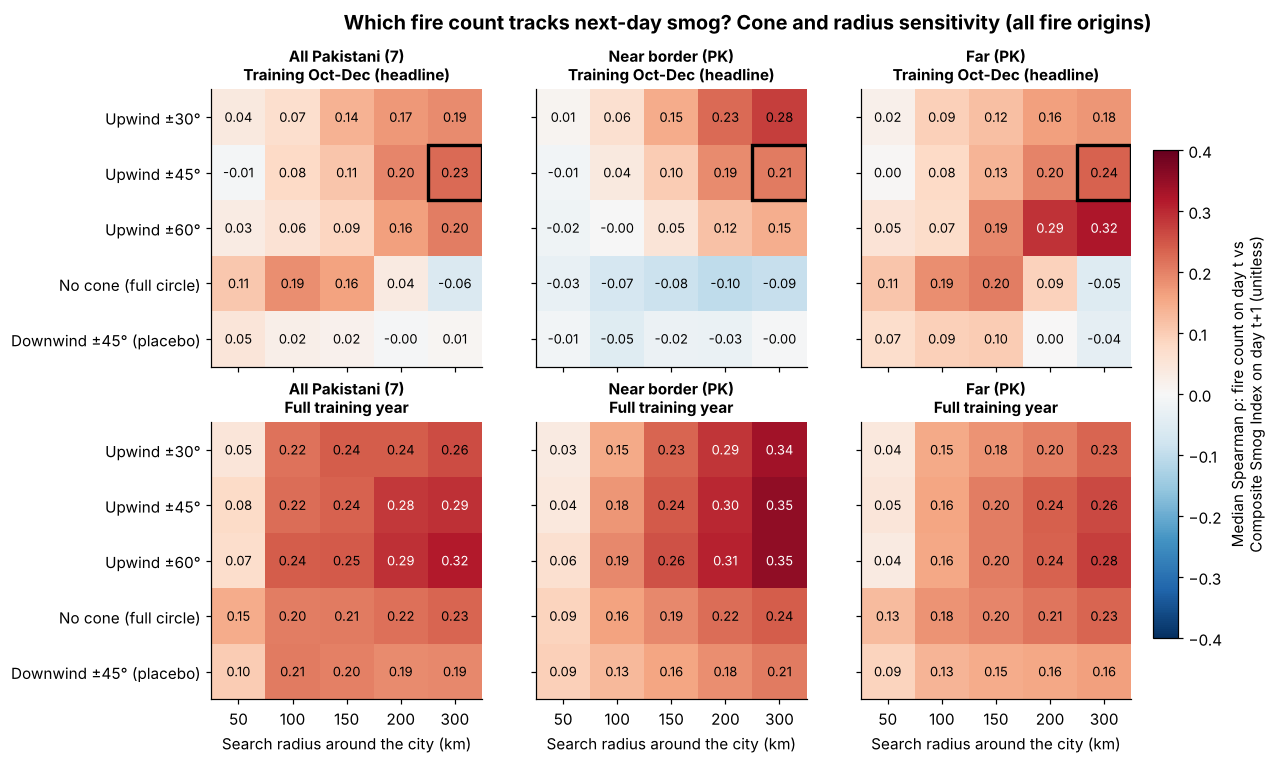

In [15]:
# Figure M1: cone and radius sensitivity heatmaps (headline period on top, full training year below)
show_groups = ["All Pakistani (7)", "Near border (PK)", "Far (PK)"]
fig, axes = plt.subplots(2, 3, figsize=(13, 7.2), sharex=True, sharey=True)
cone_labels = {"up30": "Upwind ±30°", "up45": "Upwind ±45°", "up60": "Upwind ±60°",
               "none": "No cone (full circle)", "down45": "Downwind ±45° (placebo)"}
for i, period in enumerate(PERIODS):
    for j, group in enumerate(show_groups):
        ax = axes[i, j]
        g = grid(period, group)
        im = ax.imshow(g.values, cmap=P.DIV_CMAP, vmin=-0.4, vmax=0.4, aspect="auto")
        for (r, c), v in np.ndenumerate(g.values):
            if not np.isnan(v):
                ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=8.5,
                        color="white" if abs(v) > 0.28 else "black")
        if period.startswith("Training Oct"):
            r0, c0 = CONES.index(BEST_CONE), RADII.index(BEST_RADIUS)
            ax.add_patch(mpatches.Rectangle((c0 - 0.5, r0 - 0.5), 1, 1, fill=False, lw=2.2, ec="black"))
        ax.set_xticks(range(len(RADII)), RADII)
        ax.set_yticks(range(len(CONES)), [cone_labels[c] for c in CONES])
        ax.grid(False)
        ax.set_title(f"{group}\n{period}", fontsize=10)
        if i == 1:
            ax.set_xlabel("Search radius around the city (km)")
cbar = fig.colorbar(im, ax=axes, shrink=0.8, pad=0.02)
cbar.set_label("Median Spearman ρ: fire count on day t vs\nComposite Smog Index on day t+1 (unitless)")
fig.suptitle("Which fire count tracks next-day smog? Cone and radius sensitivity (all fire origins)", fontsize=13, fontweight="bold")
P.save(fig, "fig_m1_cone_radius_sensitivity")
plt.show()

**Figure M1.** Median Spearman correlation between the number of VIIRS fire detections (confidence nominal or high, vegetation fires) on day *t*
and the Composite Smog Index on day *t + 1*, for every cone and radius setting. Correlations are computed inside each city over its own days and the
median over the cities of the group is shown. Top row: training harvest season (1 October to 31 December 2022, 92 days per city), used to choose
the setting (black box). Bottom row: the full training year (4 August 2022 to 31 August 2023, 393 days per city), where the shared seasonal cycle of fires and smog
inflates every setting, including the downwind placebo. Near border = Lahore and Sialkot; Far = Multan, Rahim Yar Khan, Islamabad and Rawalpindi.
Diverging blue-red scale centred on 0.

**What we found (step 6) and the chosen setting.**
- **Chosen default: upwind cone ±45°, radius 300 km** (median ρ = 0.23 over the 7 Pakistani cities, positive in all 7).
  The work plan had suggested 150 km. At 150 km the median is only 0.11, so the master carries the 300 km setting.
  Person C's 150 km columns stay in the master for comparison.
- **The cone matters more than the circle.** At the same 300 km radius, the plain circle gives ρ = −0.06 and the downwind placebo gives 0.01.
  A large circle counts as many fires downwind as upwind, so it carries no signal. Only fires the wind can bring to the city track next-day smog.
- **Radius.** Inside the cone, ρ grows from about 0 at 50 km to 0.23 at 300 km. The smoke that matters is regional, transported over a day or more, not local.
  The plain circle peaks at 100 km (0.19), which mostly reflects burning close to the city.
- **30° and 60°.** The near-border cities do slightly better with the narrow ±30° cone (0.28), and the far cities with the wide ±60° cone (0.32), where the wind direction is less certain over a longer path.
  Over all 7 cities the three angles are close (0.19, 0.23, 0.20). With 92 days per city a correlation has a standard error of about 1/√91 ≈ 0.10,
  so the angle differences are within noise. ±45° is kept as the middle choice. The radius effect and the cone-vs-circle gap are much larger than the angle differences.
- **Why the headline uses only October to December.** Over the full training year every 300 km setting looks good (0.16 to 0.35 across the city groups), including the downwind placebo (0.19 over the 7 Pakistani cities).
  That is the shared seasonal cycle of fires and smog, which is the bias the harvest-only headline avoids.
- **Indian Punjab cities** show almost no cone signal (0.06). Their fires burn all around them, so local smoke reaches them whatever the wind direction.

### 2A.10 Add the chosen fire setting to the master, log-transform and scale it, and save

The master keeps Person C's 150 km columns, plus three settings at the chosen radius: the chosen upwind cone, the full circle (no cone, needed to test H1)
and the downwind placebo. Counts and fire radiative power (FRP) are both kept, split by origin (IN, PK, all).
The cone counts get `log1p` (most days are 0 or small and a few are huge) and a z-score with **training-period** mean and SD only.

In [16]:
# Add the chosen setting, the plain radius and the placebo at the same radius (with lags 1-3 of the counts)
for cone in [BEST_CONE, "none", "down45"]:
    master = M.add_fire_setting(master, cone, BEST_RADIUS, START, END,
                                lag_origins=("all", "in", "pk") if cone == BEST_CONE else ("all",))
TAG = M.setting_tag(BEST_CONE, BEST_RADIUS)            # e.g. 'up45_r300'
RTAG = M.setting_tag("none", BEST_RADIUS)              # e.g. 'r300'
PTAG = M.setting_tag("down45", BEST_RADIUS)            # placebo

# log1p + training z-score for the new count columns (skewness before/after printed for the report)
is_train = master["split"] == "train"
new_cnt = [f"fire_cnt_{t}_{o}" for t in [TAG, RTAG, PTAG] for o in ["all", "in", "pk"]]
master, fire_scale = M.add_log_z(master, new_cnt, is_train)
skew_fire = pd.DataFrame({"skew_raw": master.loc[is_train, new_cnt].skew().values,
                          "skew_log1p": master.loc[is_train, [c + "_log1p" for c in new_cnt]].skew().values,
                          "share_zero_days_pct": 100 * (master.loc[is_train, new_cnt] == 0).mean().values},
                         index=new_cnt)
print(skew_fire.round(2))
_ = save_table(skew_fire.round(4), "fire_setting_skew")
print("\nMaster now:", master.shape)

                          skew_raw  skew_log1p  share_zero_days_pct
fire_cnt_up45_r300_all       9.790       0.640               26.880
fire_cnt_up45_r300_in       10.650       1.990               61.160
fire_cnt_up45_r300_pk        4.410       0.710               41.710
fire_cnt_r300_all            4.740       0.100                4.880
fire_cnt_r300_in             5.130       0.880               28.380
fire_cnt_r300_pk             2.320      -0.250                6.780
fire_cnt_down45_r300_all     7.530       0.540               16.960
fire_cnt_down45_r300_in      8.120       1.420               54.110
fire_cnt_down45_r300_pk      4.350       0.610               34.280

Master now: (5665, 287)


### Weather-trap cut-offs (training period only)

"Humid" and "large temperature range" are defined by training-period quartiles, pooled over the 11 cities, and saved.

**Change from the work plan: the temperature-range proxy points the other way.**
The plan used a *low* daily temperature range as the inversion proxy. In the data, low-range days almost never precede a spike (see step 8).
Physically, a small day-night range means clouds or rain, which mix and wash out the air. The surface inversions that trap smog form on clear, calm nights
with strong radiative cooling, and those days have a *large* range. So the trap proxy is `temp_range_c` above the training 75th percentile.
The low-range version is still reported in step 8, so the reason for the change is visible.

In [17]:
train = master[is_train]
TRAP = {
    "rh_mean_pct_p75": float(train["rh_mean_pct"].quantile(0.75)),
    "temp_range_c_p75": float(train["temp_range_c"].quantile(0.75)),
    "temp_range_c_p25": float(train["temp_range_c"].quantile(0.25)),
    "stagnant_rule": "Person B's flag: daily vector-mean wind < 2 km/h",
    "rain_free_rule": "rain_day == 0 (daily rain < 1 mm)",
}
print(json.dumps(TRAP, indent=2))

# Everything chosen on the training period in Role 2, saved in one file (reused in Week 14)
role2_params = {"window": [START, END], "train": [C.TRAIN_START, C.TRAIN_END],
                "fire_setting": {"cone": BEST_CONE, "radius_km": BEST_RADIUS, "tag": TAG,
                                 "rule": "highest median Spearman rho (fire day t vs index day t+1) over the 7 Pakistani cities, training Oct-Dec"},
                "fire_log1p_zscore": fire_scale, "weather_trap": TRAP}
with open(C.CLEAN_DIR / "role2_params.json", "w") as f:
    json.dump(role2_params, f, indent=2)

{
  "rh_mean_pct_p75": 77.0625,
  "temp_range_c_p75": 13.6,
  "temp_range_c_p25": 8.899999999999999,
  "stagnant_rule": "Person B's flag: daily vector-mean wind < 2 km/h",
  "rain_free_rule": "rain_day == 0 (daily rain < 1 mm)"
}


In [18]:
# Save the master analytical dataset and its data dictionary
master_path = C.CLEAN_DIR / "master_daily.parquet"
master.to_parquet(master_path, index=False)
dictionary = M.data_dictionary(master)
dictionary.to_csv(C.CLEAN_DIR / "master_data_dictionary.csv", index=False)

# Reload and compare, so the saved file is exactly what was analysed
reloaded = pd.read_parquet(master_path)
pd.testing.assert_frame_equal(reloaded, master, check_dtype=False)
print(f"Saved {master_path} : {master.shape[0]:,} rows x {master.shape[1]} columns (reloaded and identical)")
print("Data dictionary:", len(dictionary), "columns documented (meaning, unit, source, owner)")
print(dictionary.groupby(["owner", "source"]).size().rename("columns").to_string())
dictionary.sample(8, random_state=3)[["column", "meaning", "unit", "owner"]]

Saved Dataset/clean/master_daily.parquet : 5,665 rows x 287 columns (reloaded and identical)
Data dictionary: 287 columns documented (meaning, unit, source, owner)
owner  source                           
A      Open-Meteo Air Quality API            52
B      Open-Meteo Historical Weather API     58
       all streams                            1
       derived in merge                      46
       shared dictionary                      2
C      NASA FIRMS VIIRS (NOAA-20)           128


,column,meaning,unit,owner
207,city_amritsar,1 if city is Amritsar (reference: Lahore),0/1,B
200,index_lag3,Composite Smog Index on day t-3,z-score units,B
123,fire_frp_up45_r150_in,"Sum of fire radiative power, India-origin, wit...",MW,C
38,o3_max_z,"O3 daily max, z-score (training mean/SD, after...",z-score,A
16,co_max_ugm3,CO daily max,ug/m3,A
67,wind_dir_daily_deg,Daily wind-from direction (vector mean),deg from N,B
31,pm10_max_log,log1p of PM10 daily max,log(1+ug/m3),A
269,fire_cnt_up45_r300_all_log1p,"log1p of number of fire detections, all origin...",log(1+count),C


### 2A.11 Keep it reusable

Every step above is a function in `src/merge.py` that takes the date window, and `build_master` runs them in order.
Running it reproduces the step-by-step table, so the Week 14 run with 2024 data only needs new dates in `src/config.py`.

In [19]:
quick, _ = M.build_master(START, END, C.TRAIN_START, C.TRAIN_END, C.SKIP_START, C.SKIP_END,
                          C.VALID_START, C.VALID_END, verbose=False)
for cone in [BEST_CONE, "none", "down45"]:
    quick = M.add_fire_setting(quick, cone, BEST_RADIUS, START, END,
                               lag_origins=("all", "in", "pk") if cone == BEST_CONE else ("all",))
quick, _ = M.add_log_z(quick, new_cnt, quick["split"] == "train")
pd.testing.assert_frame_equal(quick[master.columns], master)
print("build_master() + add_fire_setting() reproduce the master exactly:", quick.shape)

build_master() + add_fire_setting() reproduce the master exactly: (5665, 287)


---
# Part 2B: Analysis on the merged data

Everything below uses the **training period** (4,323 city-days; 1,012 in October to December 2022) unless a cell says otherwise.

## Step 1. Master overview (Person B)

In [20]:
overview = pd.DataFrame({
    "value": [
        f"{master.shape[0]:,}", f"{master.shape[1]}",
        "1 row = 1 city on 1 local (UTC+5) day",
        f"{master['city'].nunique()} cities (7 Pakistani Punjab and ICT, 4 Indian Punjab)",
        f"{master['date'].min().date()} to {master['date'].max().date()} ({master['date'].nunique()} days)",
        "Open-Meteo Air Quality API (hourly, CAMS model output)",
        "Open-Meteo Historical Weather API (hourly, ERA5-based reanalysis)",
        "NASA FIRMS VIIRS NOAA-20 active fires (point detections)",
        f"train {int((master['split']=='train').sum()):,} / skip {int((master['split']=='skip').sum())} / validation {int((master['split']=='validation').sum()):,}",
    ]}, index=["Rows (observations)", "Columns (variables)", "Observational unit", "Cities", "Period",
               "Source 1: air quality", "Source 2: weather", "Source 3: fire", "Split"])
print(overview.to_string())
_ = save_table(overview, "master_overview")

owner_cols = dictionary.groupby("owner").size().rename("columns")
print("\nColumns by owner (A = AQ, B = weather and merge, C = fire):")
print(owner_cols)

                                                                                   value
Rows (observations)                                                                5,665
Columns (variables)                                                                  287
Observational unit                                 1 row = 1 city on 1 local (UTC+5) day
Cities                           11 cities (7 Pakistani Punjab and ICT, 4 Indian Punjab)
Period                                               2022-08-04 to 2023-12-31 (515 days)
Source 1: air quality             Open-Meteo Air Quality API (hourly, CAMS model output)
Source 2: weather      Open-Meteo Historical Weather API (hourly, ERA5-based reanalysis)
Source 3: fire                  NASA FIRMS VIIRS NOAA-20 active fires (point detections)
Split                                           train 4,323 / skip 33 / validation 1,309

Columns by owner (A = AQ, B = weather and merge, C = fire):
owner
A     52
B    107
C    128
Name: columns, d

In [21]:
# Missing count and percent for EVERY column of the master file
missing = pd.DataFrame({"missing_count": master.isna().sum(),
                        "missing_pct": 100 * master.isna().mean()})
missing["reason"] = ""
missing.loc[missing.index.str.startswith("target_"), "reason"] = "target day falls in 2024 (sealed)"
missing.loc[missing.index.str.startswith("index_lag"), "reason"] = "AQ starts 2022-08-04 (no earlier index)"
_ = save_table(missing.round(4), "master_missing_all_columns")
print(f"{(missing['missing_count'] == 0).sum()} of {len(missing)} columns have no missing values.")
print("Columns with missing values:")
print(missing[missing["missing_count"] > 0].round(2).to_string())
with pd.option_context("display.max_rows", 400):
    print("\nFull table (every column):")
    print(missing[["missing_count", "missing_pct"]].round(2).to_string())

278 of 287 columns have no missing values.
Columns with missing values:
                 missing_count  missing_pct                                   reason
target_index_h1             11        0.190        target day falls in 2024 (sealed)
target_spike_h1             11        0.190        target day falls in 2024 (sealed)
target_index_h2             22        0.390        target day falls in 2024 (sealed)
target_spike_h2             22        0.390        target day falls in 2024 (sealed)
target_index_h3             33        0.580        target day falls in 2024 (sealed)
target_spike_h3             33        0.580        target day falls in 2024 (sealed)
index_lag1                  11        0.190  AQ starts 2022-08-04 (no earlier index)
index_lag2                  22        0.390  AQ starts 2022-08-04 (no earlier index)
index_lag3                  33        0.580  AQ starts 2022-08-04 (no earlier index)

Full table (every column):
                                  missing_count  m

## Step 2. Combined summary table (Person B)

The key numeric variables of all three streams on the training days. Mean and SD are non-resistant (one extreme day moves them), while median and IQR
are resistant. When the mean is far above the median, the distribution is right-skewed and the median and IQR describe a typical day better.

In [22]:
KEY = {
    "composite_smog_index": "Composite Smog Index (z units)",
    "pm2_5_mean_ugm3": "PM2.5 daily mean (µg/m³)",
    "pm10_mean_ugm3": "PM10 daily mean (µg/m³)",
    "no2_mean_ugm3": "NO2 daily mean (µg/m³)",
    "co_mean_ugm3": "CO daily mean (µg/m³)",
    "temp_mean_c": "Temperature mean (°C)",
    "temp_range_c": "Temperature range (°C)",
    "rh_mean_pct": "Relative humidity (%)",
    "precip_sum_mm": "Rain total (mm)",
    "wind_speed_mean_kmh": "Wind speed mean (km/h)",
    "vec_len_kmh": "Vector-mean wind (km/h)",
    f"fire_cnt_{TAG}_all": f"Fires in upwind cone, {BEST_RADIUS} km (count)",
    f"fire_cnt_{TAG}_in": f"India-origin fires in cone (count)",
    f"fire_cnt_{RTAG}_all": f"Fires within {BEST_RADIUS} km, no cone (count)",
    f"fire_frp_{TAG}_all": "FRP in upwind cone (MW)",
}
summary = E.summary_table(train, KEY, KEY)
print(summary.round(2).to_string())
_ = save_table(summary.round(4), "summary_train")

# Pollution level: share of training city-days above the WHO 2021 24-hour PM2.5 guideline (flagged suspect days left out)
pm_ok = train.loc[train["suspect_day"] == 0, "pm2_5_mean_ugm3"]
print(f"\nPM2.5 daily mean above the WHO guideline of 15 µg/m³: {100 * (pm_ok > 15).mean():.1f}% of {len(pm_ok):,} training city-days")

                                         n    mean  median        sd     iqr   skew  mean_minus_median_in_sd  share_zero_pct
variable                                                                                                                    
Composite Smog Index (z units)        4323  -0.030  -0.040     0.830   0.910 -1.150                    0.020           0.000
PM2.5 daily mean (µg/m³)              4323  54.360  46.150    30.790  29.020  1.910                    0.270           0.000
PM10 daily mean (µg/m³)               4323  86.970  74.140    46.670  48.560  1.710                    0.270           0.000
NO2 daily mean (µg/m³)                4323  29.600  24.960    21.140  26.810  1.640                    0.220           0.510
CO daily mean (µg/m³)                 4323 854.720 616.500   735.930 658.380  3.170                    0.320           0.000
Temperature mean (°C)                 4323  23.460  25.460     7.190  11.540 -0.440                   -0.280           0.000


In [23]:
# Outlier audit on the same variables with both rules (training days); outliers are flagged, never deleted
audit = E.outlier_audit(train, KEY, KEY)
print(audit.round(2).to_string())
_ = save_table(audit.round(4), "outlier_audit_train")

# Same audit on the log scale for the two most skewed groups: after log1p most 'outliers' disappear
log_cols = {"pm2_5_mean_log": "log1p PM2.5 mean", f"fire_cnt_{TAG}_all_log1p": "log1p fires in cone",
            "precip_log1p": "log1p rain"}
print("\nAfter log1p:")
print(E.outlier_audit(train, log_cols, log_cols)[["z_outliers", "iqr_outliers", "sd_inflation_pct"]].round(2))

                                         n  z_outliers  iqr_outliers  iqr_pct  iqr_only  z_new_after_removal (masking)    sd_all  sd_without_iqr_outliers  sd_inflation_pct
variable                                                                                                                                                                   
Composite Smog Index (z units)        4323          33           110    2.540        77                             22     0.830                    0.680            22.670
PM2.5 daily mean (µg/m³)              4323          96           292    6.750       196                             63    30.790                   19.930            54.450
PM10 daily mean (µg/m³)               4323          73           232    5.370       159                             57    46.670                   33.800            38.080
NO2 daily mean (µg/m³)                4323          48            91    2.110        43                             31    21.140            

**What we found (step 2).**
- **Resistant vs non-resistant.** Fire counts and rain are zero-inflated and very right-skewed. Fires in the cone have a mean of 43.3 but a median of 4,
  with 26.9% zero days and skewness 9.8. India-origin fires in the cone are zero on 61.2% of training days, with mean 25.3 and median 0. Rain has a mean of 2.2 mm, a median of 0, and 61.2% dry days.
  For these variables the median and IQR describe a typical day, while the mean describes the total fire load and is pulled up by a few huge days.
  PM2.5 (mean 54.4, median 46.1 µg/m³, skew 1.91) and CO (skew 3.17) are moderately skewed, which is why Person A log-transformed them.
  The weather variables are close to symmetric (temperature range skew 0.02, mean 11.26 and median 11.30 °C), so mean and SD are fine there.
- **Pollution level.** Daily mean PM2.5 is above the WHO 2021 24-hour guideline (15 µg/m³) on 99.4% of the 4,279 training city-days outside the flagged days. These are model estimates, so this is an indication, not an official exceedance count.
- **The index.** Its skewness of −1.15 comes from the 44 flagged December 2022 days with almost no PM2.5. Without them the skewness is +0.26.
  Following the team decision, these days stay in every statistic and are flagged (`suspect_day`).
- **Outlier audit, both rules.** The IQR rule flags far more points than the z-rule in every skewed variable: rain 823 vs 89, fires in the cone 534 vs 63, PM2.5 292 vs 96.
- **Masking.** The extreme values inflate the SD, so the z-rule misses other extreme points. After removing the first-pass z-outliers, a second z pass flags 144 more rain days, 101 more fire days and 63 more PM2.5 days.
- **Variance inflation.** Without the IQR outliers, the SD of rain falls from 6.26 to 0.43 mm (+1,372% inflation). For fires in the cone it falls from 177 to 14.6 (+1,115%), and for PM2.5 from 30.8 to 19.9 µg/m³ (+54%).
- **The z-rule is weak for zero-inflated data.** For rain and fires the SD is mostly made of the outliers themselves.
  After `log1p`, fires in the cone have 0 IQR outliers, so the log scale is the right scale for modelling.
- **Outliers are kept and flagged, never deleted.** They are real smog crises, storms and fire outbreaks, and they are exactly the days we want to predict.

## Step 3. Correlation matrix (Person B)

Spearman rank correlations between the key variables on the **training harvest days** (October to December 2022, 1,012 city-days).
Ranks are used because fire counts and rain are mostly zero and heavily skewed. The first row/column is the next-day index (the target).

Index, day t+1 (target)      1.000
Index, day t                 0.820
Fires in cone (t)            0.340
India-origin, cone (t)       0.230
Pakistan-origin, cone (t)    0.270
Fires, 300 km circle (t)     0.190
Temperature mean            -0.170
Temperature range            0.300
Humidity                     0.320
Rain                        -0.290
Wind speed                  -0.380
Vector-mean wind            -0.310
Stagnant (0/1)               0.120


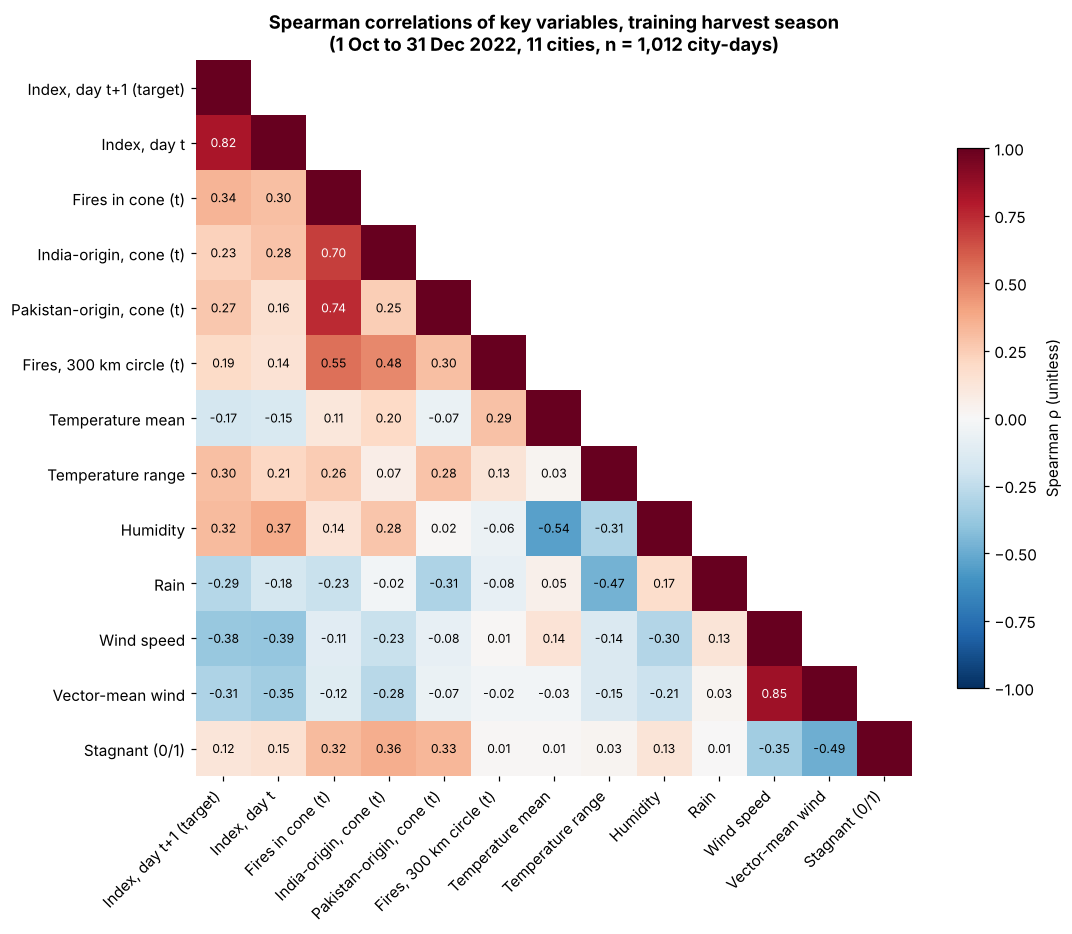

In [24]:
CORR = {"target_index_h1": "Index, day t+1 (target)", "composite_smog_index": "Index, day t",
        f"fire_cnt_{TAG}_all": "Fires in cone (t)", f"fire_cnt_{TAG}_in": "India-origin, cone (t)",
        f"fire_cnt_{TAG}_pk": "Pakistan-origin, cone (t)", f"fire_cnt_{RTAG}_all": f"Fires, {BEST_RADIUS} km circle (t)",
        "temp_mean_c": "Temperature mean", "temp_range_c": "Temperature range", "rh_mean_pct": "Humidity",
        "precip_sum_mm": "Rain", "wind_speed_mean_kmh": "Wind speed", "vec_len_kmh": "Vector-mean wind",
        "stagnant": "Stagnant (0/1)"}
harvest_train = train[train["harvest_season"] == 1]
corr = harvest_train[list(CORR)].corr(method="spearman")
corr.index = corr.columns = list(CORR.values())
_ = save_table(corr.round(4), "spearman_matrix_harvest_train")
print(corr.iloc[:, 0].round(2).to_string())

# Figure M2: lower-triangle heatmap
fig, ax = plt.subplots(figsize=(10.5, 8.5))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
shown = np.where(mask, np.nan, corr.values)
im = ax.imshow(shown, cmap=P.DIV_CMAP, vmin=-1, vmax=1)
for (r, c), v in np.ndenumerate(shown):
    if not np.isnan(v) and r != c:
        ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if abs(v) > 0.6 else "black")
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.index)
ax.grid(False)
ax.spines[["left", "bottom"]].set_visible(False)
cbar = fig.colorbar(im, ax=ax, shrink=0.75)
cbar.set_label("Spearman ρ (unitless)")
ax.set_title(f"Spearman correlations of key variables, training harvest season\n"
             f"(1 Oct to 31 Dec 2022, 11 cities, n = {len(harvest_train):,} city-days)")
P.save(fig, "fig_m2_correlation_harvest")
plt.show()

**Figure M2.** Spearman rank correlations between the next-day Composite Smog Index, today's index, fire counts (upwind cone at the chosen radius, split by origin, and the plain circle),
and daily weather on the 1,012 training harvest city-days. Temperature range is daily maximum minus minimum (°C). Rain is the daily total (mm). Wind speed is the mean of hourly speeds and
the vector-mean wind is the length of the averaged wind vector (km/h). Stagnant = vector-mean wind below 2 km/h. Pooling 11 cities mixes between-city and within-city variation.
Diverging scale centred on 0.

lag_days                       0      1      2      3
setting                                              
Downwind placebo (300 km) -0.045  0.011 -0.011  0.023
No cone (300 km)          -0.090 -0.035 -0.035 -0.058
Upwind cone 45° (300 km)   0.164  0.239  0.115  0.053


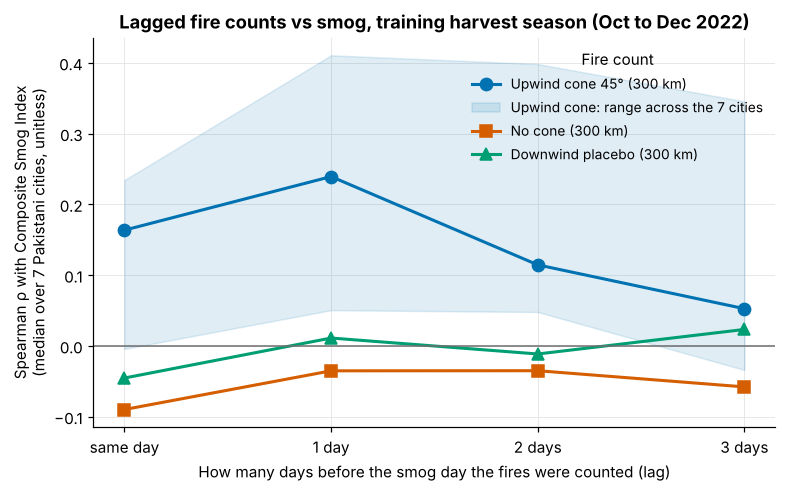

In [25]:
# Lagged fire counts (0 to 3 days before) against the index of day t, harvest training days, median over the 7 Pakistani cities
pk7 = GROUPS["All Pakistani (7)"]
lag_rows = []
for label, col in [(f"Upwind cone {BEST_CONE[2:]}° ({BEST_RADIUS} km)", f"fire_cnt_{TAG}_all"),
                   (f"No cone ({BEST_RADIUS} km)", f"fire_cnt_{RTAG}_all"),
                   (f"Downwind placebo ({BEST_RADIUS} km)", f"fire_cnt_{PTAG}_all")]:
    for k in range(4):
        x = col if k == 0 else f"{col}_lag{k}"
        rho = E.spearman_by_city(harvest_train, x, "composite_smog_index", pk7)
        lag_rows.append({"setting": label, "lag_days": k, "median_rho": rho.median(),
                         "min_rho": rho.min(), "max_rho": rho.max()})
lagged = pd.DataFrame(lag_rows)
print(lagged.pivot(index="setting", columns="lag_days", values="median_rho").round(3))
_ = save_table(lagged.round(4), "lagged_fire_correlation")

fig, ax = plt.subplots(figsize=(8, 4.6))
for (label, g), color, marker in zip(lagged.groupby("setting", sort=False), P.CAT_COLORS, ["o", "s", "^"]):
    ax.plot(g["lag_days"], g["median_rho"], marker=marker, markersize=8, color=color, label=label)
    if label.startswith("Upwind"):    # range across the 7 cities, shown for the cone only to keep the plot readable
        ax.fill_between(g["lag_days"], g["min_rho"], g["max_rho"], color=color, alpha=0.12,
                        label="Upwind cone: range across the 7 cities")
ax.axhline(0, color=P.GREY, lw=1)
ax.set_xticks(range(4), ["same day", "1 day", "2 days", "3 days"])
ax.set_xlabel("How many days before the smog day the fires were counted (lag)")
ax.set_ylabel("Spearman ρ with Composite Smog Index\n(median over 7 Pakistani cities, unitless)")
ax.set_title("Lagged fire counts vs smog, training harvest season (Oct to Dec 2022)")
ax.legend(loc="upper right", title="Fire count")
P.save(fig, "fig_m3_lagged_fire")
plt.show()

**Figure M3.** Spearman correlation between the fire count *k* days earlier (*k* = 0 to 3) and the Composite Smog Index of the day,
median over the 7 Pakistani cities (lines; the shaded band is the range across the 7 cities for the upwind cone), on the 92 training harvest days of each city.
Upwind cone and downwind placebo use ±45° around the daily vector-mean wind direction.

**What we found (lagged fire).** The upwind-cone count is most related to smog **one day later** (median ρ = 0.24), compared with 0.16 on the same day, 0.11 after two days and 0.05 after three.
The 0.24 differs slightly from the 0.23 of step 6 because here the 92-day window is set on the smog day, and in step 6 on the fire day.
This fits regional transport. At the median vector-mean wind of about 5 km/h, smoke covers roughly 120 km a day, so fires 100 to 300 km upwind arrive after one to two days.
The no-cone and placebo counts stay near zero at every lag (−0.09 to 0.02). The master keeps lags 1 to 3 of the cone counts for modelling.

## Step 4. Group-by and contingency tables (Person A)

Average index and the share of spike days by group, on the training days. `smog_spike` is the same-day label.
By construction about 10% of training October to March days are spikes in each city, because the threshold is the 90th percentile of those days.

In [26]:
def by(group_col, data=train, labels=None):
    out = data.groupby(group_col).agg(city_days=("date", "size"), mean_index=("composite_smog_index", "mean"),
                                      median_index=("composite_smog_index", "median"),
                                      spike_share_pct=("smog_spike", lambda s: 100 * s.mean()))
    if labels:
        out.index = [labels.get(i, i) for i in out.index]
    return out

tables = {
    "city": by("city").reindex(list(C.CITY_COUNTRY)),
    "country": by("country", labels={"PK": "Pakistan", "IN": "India"}),
    "month": by(train["date"].dt.month),
    "season": by("harvest_season", labels={0: "Jan-Sep", 1: "Oct-Dec (harvest)"}),
    "stagnant": by("stagnant", labels={0: "ventilated", 1: "stagnant (< 2 km/h)"}),
    "rain": by("rain_day", labels={0: "no rain (< 1 mm)", 1: "rain day"}),
}
for name, t in tables.items():
    print(f"\n--- by {name} (training days) ---")
    print(t.round(2).to_string())
    save_table(t.round(4), f"groupby_{name}")


--- by city (training days) ---
                city_days  mean_index  median_index  spike_share_pct
city                                                                
Lahore                393       0.630         0.570            4.580
Faisalabad            393       0.230         0.150            4.580
Multan                393      -0.060        -0.130            4.580
Rawalpindi            393      -0.060        -0.010            5.850
Sialkot               393      -0.040        -0.090            4.580
Rahim Yar Khan        393      -0.790        -0.850            4.580
Islamabad             393      -0.060        -0.010            5.850
Amritsar              393       0.050        -0.040            4.580
Ferozepur             393      -0.140        -0.240            4.580
Ludhiana              393       0.020         0.040            4.580
Jalandhar             393      -0.090        -0.160            4.580

--- by country (training days) ---
          city_days  mean_index  m

In [27]:
# Same group-bys inside the training harvest season only (Oct-Dec 2022)
for name, col, lab in [("stagnant", "stagnant", {0: "ventilated", 1: "stagnant"}),
                       ("rain", "rain_day", {0: "no rain", 1: "rain day"}),
                       ("country", "country", {"PK": "Pakistan", "IN": "India"})]:
    t = by(col, harvest_train, lab)
    print(f"\n--- by {name}, training Oct-Dec ---")
    print(t.round(2).to_string())
    save_table(t.round(4), f"groupby_{name}_harvest")


--- by stagnant, training Oct-Dec ---
            city_days  mean_index  median_index  spike_share_pct
ventilated        924       0.360         0.410            9.960
stagnant           88       0.790         0.770           21.590

--- by rain, training Oct-Dec ---
          city_days  mean_index  median_index  spike_share_pct
no rain         940       0.420         0.500           11.810
rain day         72       0.110         0.150            0.000

--- by country, training Oct-Dec ---
          city_days  mean_index  median_index  spike_share_pct
India           368       0.460         0.600           11.140
Pakistan        644       0.360         0.360           10.870


In [28]:
# Contingency tables on the training harvest days: is tomorrow a spike, given today's condition?
ht = harvest_train.assign(spike_next=harvest_train["target_spike_h1"].astype(float),
                          fire_in_cone=(harvest_train[f"fire_cnt_{TAG}_all"] > 0).astype(int))
cont = {}
for name, col, labs in [("stagnant", "stagnant", {0: "ventilated today", 1: "stagnant today"}),
                        ("fire_in_cone", "fire_in_cone", {0: "no fire in cone today", 1: ">= 1 fire in cone today"})]:
    tab, res = E.contingency(ht, col, "spike_next", labs, {0: "no spike tomorrow", 1: "spike tomorrow"})
    tab["spike_rate_pct"] = 100 * tab.iloc[:, 1] / tab.sum(axis=1)
    cont[name] = res
    print(f"\n{name}:")
    print(tab.round(1).to_string())
    print(f"chi-square = {res['chi2']:.2f}, p = {res['p_value']:.4f}, odds ratio = {res['odds_ratio']:.2f} "
          f"(95% CI {res['or_ci95'][0]:.2f} to {res['or_ci95'][1]:.2f})")
    save_table(tab.round(4), f"contingency_{name}")
print("\nCaveat: consecutive days of the same city are not independent (smog episodes last several days),"
      "\nso these p-values are too small; they describe association, not a formal test.")


stagnant:
                  no spike tomorrow  spike tomorrow  spike_rate_pct
ventilated today                837              87           9.400
stagnant today                   64              24          27.300
chi-square = 24.44, p = 0.0000, odds ratio = 3.61 (95% CI 2.15 to 6.06)

fire_in_cone:
                         no spike tomorrow  spike tomorrow  spike_rate_pct
no fire in cone today                  112               3           2.600
>= 1 fire in cone today                789             108          12.000
chi-square = 8.34, p = 0.0039, odds ratio = 5.11 (95% CI 1.60 to 16.37)



Caveat: consecutive days of the same city are not independent (smog episodes last several days),
so these p-values are too small; they describe association, not a formal test.


**What we found (step 4).**
- **Spikes are a December–January event, while fires peak in October–November.** In training, 26.1% of December days and 22.9% of January days are spikes, against 2.4% in October and 4.2% in November.
  Fires in the cone peak in October (57,087) and November (50,062). The second fire peak, the wheat-burning season in May 2023 (30,235 cone fires), produces **no** spikes at all.
  So fires alone do not make a spike: winter weather has to trap the smoke. This is the motivation for H2 and H3.
- **Season.** The mean index is 0.39 in October to December against −0.16 in the rest of the training year, and the spike share is 11.0% against 2.9%.
- **Cities.** Lahore has the highest mean index (0.63) and Rahim Yar Khan the lowest (−0.79). Each city has about 4.6% spike days over the training year
  (5.9% for Islamabad and Rawalpindi), because each city has its own threshold.
- **Country.** India and Pakistan are very similar (spike share 4.6% vs 4.9%).
- **Weather.** Stagnant days have a mean index of 0.19 against −0.06 on ventilated days, and twice the spike share (8.7% vs 4.3%). Only 0.5% of rain days are spikes, against 6.2% of dry days.
- **Contingency tables (training harvest).**
  - After a stagnant day, 27.3% of next days are spikes, against 9.4% after a ventilated day (odds ratio 3.61, 95% CI 2.15 to 6.06).
  - After a day with at least one fire in the cone, 12.0% are spikes, against 2.6% after a day with none (odds ratio 5.11, 95% CI 1.60 to 16.37).
  - Only 115 harvest city-days had no cone fire, which is why that interval is wide.

## Step 5. Index by weather condition (Person A)

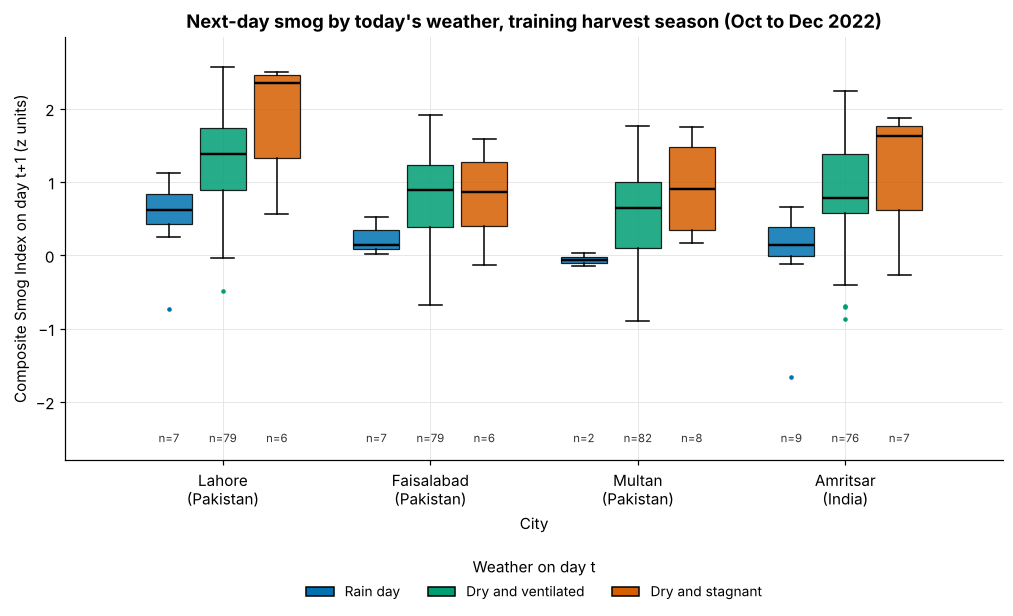

In [29]:
# Figure M4: next-day index by today's weather condition, four cities (three Pakistani, one Indian), training harvest days
cities4 = ["Lahore", "Faisalabad", "Multan", "Amritsar"]
cond = np.select([harvest_train["rain_day"] == 1, harvest_train["stagnant"] == 1],
                 ["Rain day", "Dry and stagnant"], default="Dry and ventilated")
d4 = harvest_train.assign(condition=cond)
order = ["Rain day", "Dry and ventilated", "Dry and stagnant"]
colors = {"Rain day": P.CAT_COLORS[0], "Dry and ventilated": P.CAT_COLORS[2], "Dry and stagnant": P.CAT_COLORS[1]}

fig, ax = plt.subplots(figsize=(11, 5))
width = 0.26
for i, city in enumerate(cities4):
    for j, c in enumerate(order):
        vals = d4.loc[(d4["city"] == city) & (d4["condition"] == c), "target_index_h1"].dropna()
        if len(vals) == 0:
            continue
        pos = i + (j - 1) * width
        ax.boxplot(vals, positions=[pos], widths=width * 0.85, patch_artist=True, showfliers=True,
                   medianprops=dict(color="black", lw=1.6),
                   boxprops=dict(facecolor=colors[c], alpha=0.85, edgecolor="black", lw=0.8),
                   flierprops=dict(marker="o", markersize=3, markerfacecolor=colors[c], markeredgecolor="none"))
        ax.text(pos, -2.55, f"n={len(vals)}", ha="center", fontsize=7.5, color="#333333")
ax.set_xticks(range(len(cities4)), [f"{c}\n({'India' if C.CITY_COUNTRY[c] == 'IN' else 'Pakistan'})" for c in cities4])
ax.set_ylim(-2.8, None)
ax.set_ylabel("Composite Smog Index on day t+1 (z units)")
ax.set_xlabel("City")
ax.set_title("Next-day smog by today's weather, training harvest season (Oct to Dec 2022)")
ax.legend(handles=[mpatches.Patch(facecolor=colors[c], edgecolor="black", label=c) for c in order],
          title="Weather on day t", loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3)
P.save(fig, "fig_m4_index_by_weather")
plt.show()

**Figure M4.** Composite Smog Index on the next day by today's weather condition, for three Pakistani cities and Amritsar (India),
training harvest season (October to December 2022). Rain day = at least 1 mm of rain. Stagnant = vector-mean wind below 2 km/h. Ventilated = the rest of the dry days.
Boxes show the median and IQR, whiskers extend to 1.5 x IQR and dots are days beyond them. *n* = city-days in each box.

**What we found (step 5).** In all four cities, rain days are followed by the cleanest next day. Over all 11 cities the median next-day index is −0.06 after rain days, against 0.46 after dry ventilated days and 0.80 after dry stagnant days.
After a stagnant day the median next-day index is highest in Lahore (2.36 vs 1.38 when ventilated), Amritsar (1.63 vs 0.78) and Multan (0.91 vs 0.64).
In Faisalabad it is the same as after a ventilated day (0.86 vs 0.89). The rain and stagnant boxes hold only 2 to 9 days per city, so this figure describes the pattern and does not test it.

## Step 7. Cross-border check (Person C)

For each city: how many fires of each origin fall inside the chosen upwind cone during the training harvest season, on how many days,
and how each origin's count correlates with the next-day index. A city can only test the cross-border claim if India-origin fires reach its
cone on enough days. We use at least 20 of the 92 days as the working rule.

In [30]:
xb_rows = []
for city in C.CITY_COUNTRY:
    g = harvest_train[harvest_train["city"] == city]
    row = {"city": city, "group": next(k for k, v in GROUPS.items() if k != "All Pakistani (7)" and city in v)}
    for o in ["in", "pk"]:
        col = f"fire_cnt_{TAG}_{o}"
        row[f"{o.upper()}_fires"] = int(g[col].sum())
        row[f"{o.upper()}_fire_days"] = int((g[col] > 0).sum())
        row[f"rho_{o.upper()}_next_day"] = E.spearman_by_city(g, col, "target_index_h1").iloc[0]
    row["IN_share_pct"] = 100 * row["IN_fires"] / max(row["IN_fires"] + row["PK_fires"], 1)
    row["can_test_cross_border"] = (row["IN_fire_days"] >= 20) if C.CITY_COUNTRY[city] == "PK" else "n/a (Indian city)"
    xb_rows.append(row)
cross_border = pd.DataFrame(xb_rows).set_index("city")
print(cross_border.round(2).to_string())
_ = save_table(cross_border.round(4), "cross_border")

                            group  IN_fires  IN_fire_days  rho_IN_next_day  PK_fires  PK_fire_days  rho_PK_next_day  IN_share_pct can_test_cross_border
city                                                                                                                                                   
Lahore           Near border (PK)      8823            54           -0.040      3810            77            0.230        69.840                  True
Faisalabad      Intermediate (PK)     12405            40            0.120      4355            89            0.140        74.020                  True
Multan                   Far (PK)      1343            18           -0.060      3357            85            0.050        28.570                 False
Rawalpindi               Far (PK)        40             5            0.180       759            60            0.410         5.010                 False
Sialkot          Near border (PK)      1914            45            0.330      1574    

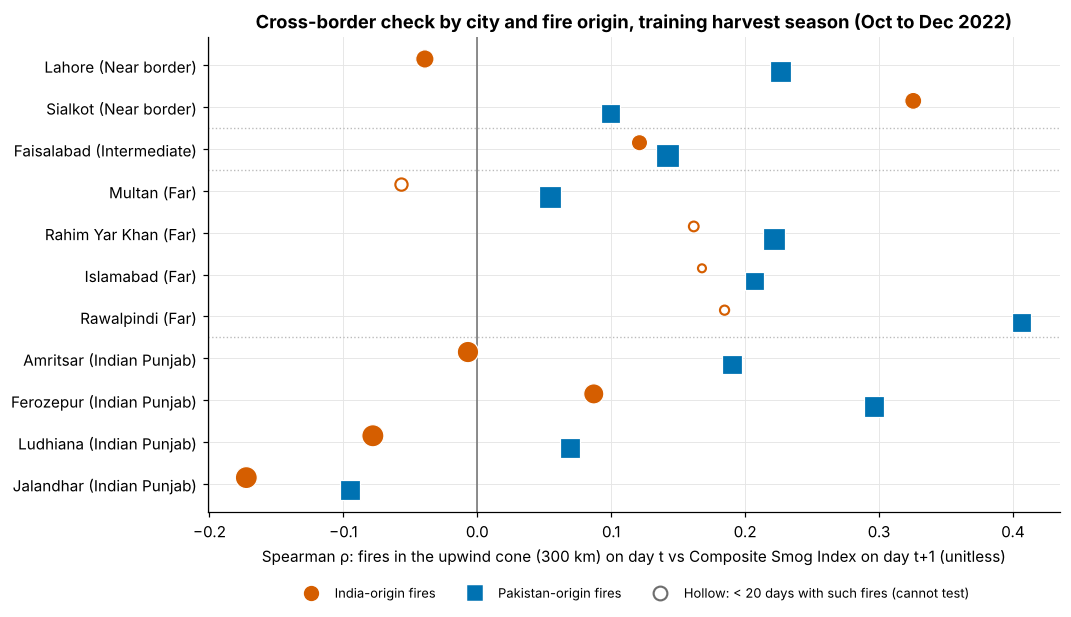

In [31]:
# Figure M5: rho by origin for each city, marker size = days with at least one fire of that origin
fig, ax = plt.subplots(figsize=(10, 5.6))
cities_order = C.NEAR_BORDER + C.INTERMEDIATE + C.FAR_PK + C.IN_CITIES   # grouped top to bottom
y = np.arange(len(cities_order))[::-1]
for o, dy, marker in [("IN", 0.15, "o"), ("PK", -0.15, "s")]:
    days = cross_border[f"{o}_fire_days"].reindex(cities_order)
    rho = cross_border[f"rho_{o}_next_day"].reindex(cities_order)
    enough = days >= 20
    ax.scatter(rho[enough], (y + dy)[enough.values], s=25 + 2.2 * days[enough], marker=marker,
               color=P.ORIGIN_COLORS[o], edgecolor="white", lw=0.8, zorder=3,
               label="_")
    ax.scatter(rho[~enough], (y + dy)[~enough.values], s=25 + 2.2 * days[~enough], marker=marker,
               facecolor="white", edgecolor=P.ORIGIN_COLORS[o], lw=1.4, zorder=3,
               label="_")
ax.axvline(0, color=P.GREY, lw=1)
ax.set_yticks(y, [f"{c} ({cross_border.loc[c, 'group'].replace(' (PK)', '')})" for c in cities_order])
ax.set_xlabel(f"Spearman ρ: fires in the upwind cone ({BEST_RADIUS} km) on day t vs Composite Smog Index on day t+1 (unitless)")
ax.set_title("Cross-border check by city and fire origin, training harvest season (Oct to Dec 2022)")
handles = [Line2D([], [], ls="", marker="o", ms=9, color=P.ORIGIN_COLORS["IN"], label="India-origin fires"),
           Line2D([], [], ls="", marker="s", ms=9, color=P.ORIGIN_COLORS["PK"], label="Pakistan-origin fires"),
           Line2D([], [], ls="", marker="o", ms=9, markerfacecolor="white", markeredgecolor=P.GREY, mew=1.4,
                  label="Hollow: < 20 days with such fires (cannot test)")]
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=3, fontsize=8.5)
for yy in [len(cities_order) - 2.5, len(cities_order) - 3.5, len(cities_order) - 7.5]:   # group separators
    ax.axhline(yy, color="#BBBBBB", lw=0.9, ls=":")
P.save(fig, "fig_m5_cross_border")
plt.show()

**Figure M5.** Spearman correlation between the number of fires inside each city's upwind cone on day *t* and the next-day Composite Smog Index,
separately for fires detected in India (circles) and in Pakistan (squares), training harvest season (92 days per city).
Marker area grows with the number of days that had at least one fire of that origin in the cone. Hollow markers mark fewer than 20 such days, too few to test the origin.
Cities are grouped (top to bottom) into near border, intermediate and far Pakistani cities, then Indian Punjab.

**What we found (step 7): which cities can test the cross-border claim.**
- **Pakistani cities that can test it:** Lahore (54 days with India-origin fires in the cone), Sialkot (45) and Faisalabad (40).
  - In Sialkot, India-origin fires go with higher next-day smog (ρ = 0.33), more than Pakistan-origin fires (0.10).
  - In Lahore it is the other way round (India −0.04, Pakistan 0.23), even though 70% of the fires in Lahore's cone are Indian.
  - Faisalabad is in between (0.12 and 0.14).
  - So the cross-border signal is mixed, even near the border. With one training season this is a description, not a test. H4 tests it formally with controls.
- **Pakistani cities that cannot test it:** Multan (18 days), Rahim Yar Khan (7), Rawalpindi (5) and Islamabad (1). India-origin fires almost never reach their cone.
  For them only Pakistan-origin fires can be studied (ρ = 0.05 to 0.41).
- **Indian Punjab cities.** The cross-border question is reversed: does Pakistan-origin smoke reach Indian cities?
  Ferozepur (0.30) and Amritsar (0.19) show a positive Pakistan-origin association. Their local India-origin fires do not (−0.17 to 0.09), probably because local fires are counted all around a city whatever the wind.

## Step 8. Weather-trap check (Person B)

Next-day spike rate (`target_spike_h1`) on days with each trap condition, against all other days, with 95% Wilson intervals.
Shown for the training harvest season (headline) and for the full training year.

In [32]:
def trap_conditions(d):
    return {
        "Stagnant (vector wind < 2 km/h)": d["stagnant"] == 1,
        f"Humid (RH > {TRAP['rh_mean_pct_p75']:.1f}%, train P75)": d["rh_mean_pct"] > TRAP["rh_mean_pct_p75"],
        "Rain-free (< 1 mm)": d["rain_day"] == 0,
        f"Large temp. range (> {TRAP['temp_range_c_p75']:.1f} °C, train P75)": d["temp_range_c"] > TRAP["temp_range_c_p75"],
        f"Small temp. range (< {TRAP['temp_range_c_p25']:.1f} °C, train P25; work-plan proxy)": d["temp_range_c"] < TRAP["temp_range_c_p25"],
        "Stagnant + rain-free + humid": (d["stagnant"] == 1) & (d["rain_day"] == 0) & (d["rh_mean_pct"] > TRAP["rh_mean_pct_p75"]),
    }

trap = {}
for name, d in [("Training Oct-Dec (headline)", harvest_train), ("Full training year", train)]:
    trap[name] = E.rate_by_condition(d, trap_conditions(d), "target_spike_h1")
    print(f"\n--- {name} ---")
    print(trap[name].round(2).to_string())
_ = save_table(trap["Training Oct-Dec (headline)"].round(4), "weather_trap_harvest")
_ = save_table(trap["Full training year"].round(4), "weather_trap_fullyear")


--- Training Oct-Dec (headline) ---
                                                          days_with  spike_rate_with_pct  ci95_low_pct  ci95_high_pct  days_without  spike_rate_without_pct  risk_ratio
condition                                                                                                                                                              
Stagnant (vector wind < 2 km/h)                                  88               27.270        19.070         37.380           924                   9.420       2.900
Humid (RH > 77.1%, train P75)                                   186               22.040        16.680         28.530           826                   8.470       2.600
Rain-free (< 1 mm)                                              940               11.810         9.900         14.030            72                   0.000         NaN
Large temp. range (> 13.6 °C, train P75)                        345               15.360        11.940         19.550      

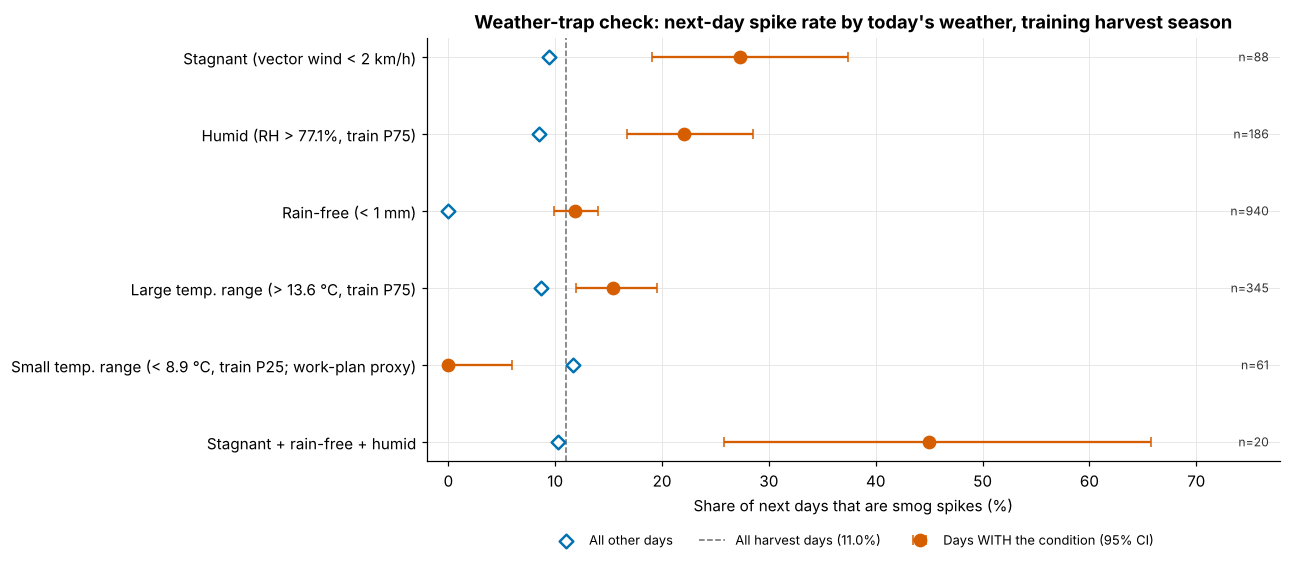

In [33]:
# Figure M6: spike rate with and without each condition (training harvest season)
t = trap["Training Oct-Dec (headline)"].iloc[::-1]
base_rate = 100 * harvest_train["target_spike_h1"].astype(float).mean()
fig, ax = plt.subplots(figsize=(10, 5))
yy = np.arange(len(t))
ax.errorbar(t["spike_rate_with_pct"], yy, xerr=[t["spike_rate_with_pct"] - t["ci95_low_pct"], t["ci95_high_pct"] - t["spike_rate_with_pct"]],
            fmt="o", color=P.CAT_COLORS[1], markersize=8, capsize=3, lw=1.5, label="Days WITH the condition (95% CI)")
ax.scatter(t["spike_rate_without_pct"], yy, marker="D", s=40, facecolor="white", edgecolor=P.CAT_COLORS[0], lw=1.6,
           zorder=3, label="All other days")
ax.axvline(base_rate, color=P.GREY, ls="--", lw=1, label=f"All harvest days ({base_rate:.1f}%)")
xmax = max(70, float(t["ci95_high_pct"].max()) + 12)
for i, (idx, r) in enumerate(t.iterrows()):
    ax.text(xmax - 1, i, f"n={int(r['days_with'])}", va="center", ha="right", fontsize=8, color="#333333")
ax.set_yticks(yy, t.index)
ax.set_xlim(-2, xmax)
ax.set_xlabel("Share of next days that are smog spikes (%)")
ax.set_title("Weather-trap check: next-day spike rate by today's weather, training harvest season")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3, fontsize=8.5)
P.save(fig, "fig_m6_weather_trap")
plt.show()

**Figure M6.** Share of next days that are smog spikes (`target_spike_h1`) when today has each weather condition (filled circles with 95% Wilson intervals)
and on all other days (hollow diamonds), on the 1,012 training harvest city-days (1 October to 31 December 2022). The dashed line is the rate over all harvest days.
Humidity and temperature-range cut-offs are training-period quartiles pooled over the 11 cities. *n* = city-days with the condition.

In [34]:
# Season x stagnation contrasts (training period): mean index and spike share for each combination
season_stag = (train.assign(season=np.where(train["harvest_season"] == 1, "Oct-Dec", "Jan-Sep"),
                            wind=np.where(train["stagnant"] == 1, "stagnant", "ventilated"))
                    .groupby(["season", "wind"]).agg(city_days=("date", "size"),
                                                      mean_index=("composite_smog_index", "mean"),
                                                      spike_share_pct=("smog_spike", lambda s: 100 * s.mean()),
                                                      mean_pm2_5_ugm3=("pm2_5_mean_ugm3", "mean")))
print(season_stag.round(2).to_string())
_ = save_table(season_stag.round(4), "season_by_stagnation")

                    city_days  mean_index  spike_share_pct  mean_pm2_5_ugm3
season  wind                                                               
Jan-Sep stagnant          382       0.060            5.760           54.330
        ventilated       2929      -0.190            2.560           46.790
Oct-Dec stagnant           88       0.790           21.590           96.410
        ventilated        924       0.360            9.960           74.350


**What we found (step 8): weather-trap check, training harvest season.**
- **Stagnant days:** 27.3% of next days are spikes, against 9.4% after other days (risk ratio 2.9).
- **Humid days:** 22.0% against 8.5% (risk ratio 2.6).
- **Rain:** not one rain day was followed by a spike (0 of 72). Rain-free days are followed by 11.8%.
- **Temperature range:** large-range days (above 13.6 °C) are followed by 15.4% spikes, against 8.7% (risk ratio 1.77).
  The work plan's small-range proxy goes the other way: 0 of 61 small-range days were followed by a spike, against 11.7% for the rest.
  So we use a large range (clear-night radiative inversion) as the trap proxy and a small range as a sign of clouds or rain.
- **The traps combine.** Days that are stagnant, rain-free and humid at the same time are followed by a spike 45% of the time (9 of 20 days), against 10.3% for the rest (risk ratio 4.4).
- **Full training year:** the same directions, with smaller rates.
- **Season x stagnation:** stagnant harvest days average PM2.5 = 96.4 µg/m³ and a 21.6% spike share, against 74.3 µg/m³ and 10.0% on ventilated harvest days.

### Step 8b. Weather-stream tables used in Person B's report

Some tables and correlations in the weather report were computed outside `weather.ipynb`. They are reproduced here from the saved
weather table, so every number in the report comes from a notebook: wind-sector shares (Table 4), season and stagnation contrasts (Table 6),
rain and stagnant days per city (Table 7), the weather correlations, and the weather correlation heatmap (Figure 2 of that report).

In [35]:
wx_all = M.load_weather("2022-01-01", END)                       # the whole cleaned weather table (2022-2023)
wx_train = wx_all[(wx_all["date"] >= C.TRAIN_START) & (wx_all["date"] <= C.TRAIN_END)]
wx_harv = wx_train[wx_train["date"].dt.month.isin([10, 11, 12])]

# Table 4: wind-from sector by country, training harvest season (calm = stagnant days)
sector = M.wind_sector(wx_harv["wind_dir_daily_deg"], wx_harv["stagnant"])
t4 = (pd.crosstab(wx_harv["country"], sector, normalize="index") * 100)[["n", "ne", "e", "se", "s", "sw", "w", "nw", "calm"]]
print("Table 4 (% of city-days, Oct-Dec 2022):"); print(t4.round(1))
_ = save_table(t4.round(2), "wx_sector_by_country_harvest")

# Table 6: weather by season half and by stagnation, training period
def wx_means(g):
    return g.agg(city_days=("date", "size"), temp_mean_c=("temp_mean_c", "mean"), temp_range_c=("temp_range_c", "mean"),
                 rh_mean_pct=("rh_mean_pct", "mean"), rain_days_pct=("rain_day", lambda s: 100 * s.mean()),
                 wind_speed_mean_kmh=("wind_speed_mean_kmh", "mean"), stagnant_pct=("stagnant", lambda s: 100 * s.mean()))
half = np.where(wx_train["date"].dt.month.isin([10, 11, 12, 1, 2, 3]), "October to March", "April to September")
t6 = pd.concat([wx_means(wx_train.groupby(half)),
                wx_means(wx_train.groupby(wx_train["stagnant"].map({1: "Stagnant days", 0: "Other days"})))])
print("\nTable 6:"); print(t6.round(2))
_ = save_table(t6.round(4), "wx_season_stagnation")

# Table 7: rain days per city (all 2022-2023 days) and stagnant days per city (training Oct-Dec)
t7 = pd.DataFrame({"rain_days_pct": wx_all.groupby("city")["rain_day"].mean() * 100,
                   "stagnant_days_harvest_pct": wx_harv.groupby("city")["stagnant"].mean() * 100}).reindex(list(C.CITY_COUNTRY))
t7.loc["All cities"] = [100 * wx_all["rain_day"].mean(), 100 * wx_harv["stagnant"].mean()]
print("\nTable 7:"); print(t7.round(1))
_ = save_table(t7.round(2), "wx_city_rain_stagnant")

# Stagnant x rain contingency (training period)
print("\nStagnant x rain day (training):"); print(pd.crosstab(wx_train["stagnant"], wx_train["rain_day"], margins=True))

Table 4 (% of city-days, Oct-Dec 2022):
col_0        n     ne      e    se     s    sw     w     nw   calm
country                                                           
IN       9.800  4.300 13.600 8.200 1.600 0.300 8.700 40.800 12.800
PK      15.100 11.600  8.200 5.300 4.000 6.800 9.300 33.200  6.400

Table 6:
                    city_days  temp_mean_c  temp_range_c  rh_mean_pct  rain_days_pct  wind_speed_mean_kmh  stagnant_pct
April to September       2321       28.770        10.280       63.760         34.940                7.880        12.670
October to March         2002       17.290        12.400       66.040         12.990                7.430         8.790
Other days               3853       23.330        11.260       64.300         24.890                7.960         0.000
Stagnant days             470       24.500        11.300       69.030         23.830                5.310       100.000

Table 7:
                rain_days_pct  stagnant_days_harvest_pct
city           

humidity vs temperature range        -0.650
temperature range vs log rain        -0.560
humidity vs log rain                  0.420
wind speed vs vector-mean wind        0.880
stagnant vs wind speed               -0.320
stagnant vs vector-mean wind         -0.460
V vs temperature mean                 0.460
U vs log rain                        -0.430
Spearman rain vs humidity             0.460
Spearman rain vs temperature range   -0.620


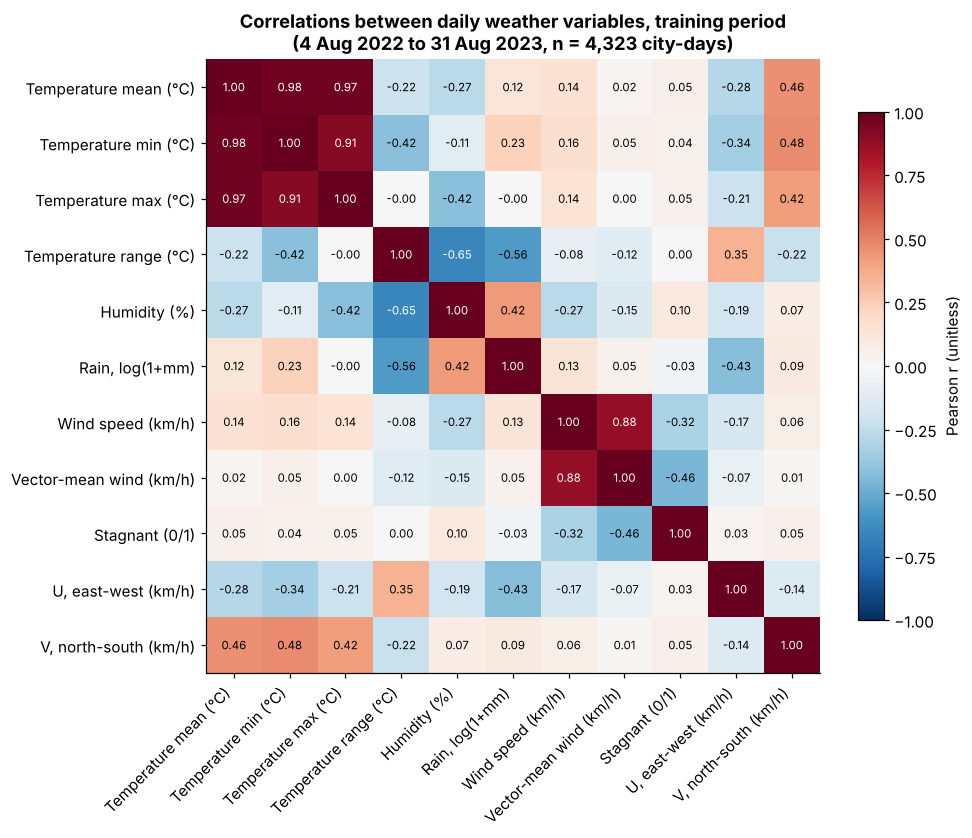

In [36]:
# Weather correlations (training period): Pearson, plus Spearman for the rain pairs
WXC = {"temp_mean_c": "Temperature mean (°C)", "temp_min_c": "Temperature min (°C)", "temp_max_c": "Temperature max (°C)",
       "temp_range_c": "Temperature range (°C)", "rh_mean_pct": "Humidity (%)", "precip_log1p": "Rain, log(1+mm)",
       "wind_speed_mean_kmh": "Wind speed (km/h)", "vec_len_kmh": "Vector-mean wind (km/h)", "stagnant": "Stagnant (0/1)",
       "u_mean": "U, east-west (km/h)", "v_mean": "V, north-south (km/h)"}
pear = wx_train[list(WXC)].corr()
pear.index = pear.columns = list(WXC.values())
_ = save_table(pear.round(4), "wx_pearson_train")
sp = wx_train[["precip_sum_mm", "rh_mean_pct", "temp_range_c"]].corr(method="spearman")
pairs = {"humidity vs temperature range": pear.loc["Humidity (%)", "Temperature range (°C)"],
         "temperature range vs log rain": pear.loc["Temperature range (°C)", "Rain, log(1+mm)"],
         "humidity vs log rain": pear.loc["Humidity (%)", "Rain, log(1+mm)"],
         "wind speed vs vector-mean wind": pear.loc["Wind speed (km/h)", "Vector-mean wind (km/h)"],
         "stagnant vs wind speed": pear.loc["Stagnant (0/1)", "Wind speed (km/h)"],
         "stagnant vs vector-mean wind": pear.loc["Stagnant (0/1)", "Vector-mean wind (km/h)"],
         "V vs temperature mean": pear.loc["V, north-south (km/h)", "Temperature mean (°C)"],
         "U vs log rain": pear.loc["U, east-west (km/h)", "Rain, log(1+mm)"],
         "Spearman rain vs humidity": sp.loc["precip_sum_mm", "rh_mean_pct"],
         "Spearman rain vs temperature range": sp.loc["precip_sum_mm", "temp_range_c"]}
print(pd.Series(pairs).round(2).to_string())

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(pear.values, cmap=P.DIV_CMAP, vmin=-1, vmax=1)
for (r, c), v in np.ndenumerate(pear.values):
    ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=7.5, color="white" if abs(v) > 0.6 else "black")
ax.set_xticks(range(len(pear)), pear.columns, rotation=45, ha="right")
ax.set_yticks(range(len(pear)), pear.index)
ax.grid(False)
cbar = fig.colorbar(im, ax=ax, shrink=0.8)
cbar.set_label("Pearson r (unitless)")
ax.set_title(f"Correlations between daily weather variables, training period\n(4 Aug 2022 to 31 Aug 2023, n = {len(wx_train):,} city-days)")
P.save(fig, "fig_b3_weather_correlation")
plt.show()

In [37]:
# Monthly weather by country, training period (supports the monthly statements in the weather report)
monthly = (wx_train.assign(month=wx_train["date"].dt.to_period("M").astype(str))
                   .groupby(["month", "country"])
                   .agg(rh_mean_pct=("rh_mean_pct", "mean"), temp_range_c=("temp_range_c", "mean"),
                        rain_days_pct=("rain_day", lambda s: 100 * s.mean()), stagnant_pct=("stagnant", lambda s: 100 * s.mean()))
                   .unstack("country"))
print(monthly.round(1).to_string())
_ = save_table(monthly.round(2), "wx_monthly_by_country")

        rh_mean_pct        temp_range_c        rain_days_pct        stagnant_pct       
country          IN     PK           IN     PK            IN     PK           IN     PK
month                                                                                  
2022-08      80.200 75.000        7.100  7.600        51.800 45.400       17.900 11.200
2022-09      75.300 66.800        8.600  9.500        20.800 22.400       28.300 13.800
2022-10      68.200 51.700       12.300 13.000         7.300  3.200       19.400  4.600
2022-11      73.300 62.400       12.600 12.000        14.200 13.300       11.700  4.800
2022-12      77.900 67.600       12.600 12.700         1.600  4.100        7.300  9.700
2023-01      83.600 70.800       10.600 11.300        18.500 14.700       11.300  8.300
2023-02      68.300 57.500       13.900 13.500         9.800 10.200       12.500  4.600
2023-03      69.600 60.000       12.500 12.100        29.800 30.000       12.900  7.800
2023-04      49.900 46.900      

## Step 9. Index weight check (Person A)

Person A rebuilt the index with three other weightings and compared it with the main index on all 5,665 days. Here the comparison is repeated on the
**training days only**, with spike thresholds re-learned for each version from training October to March days, as the shared rules require.

In [38]:
ALT = {"main (PM2.5 0.40, others 0.12)": aq_params["index_weights"],
       "equal weights (1/6 each)": {k: 1 / 6 for k in aq_params["index_weights"]},
       "without ozone": {"pm2_5": 0.40, "pm10": 0.15, "no2": 0.15, "so2": 0.15, "co": 0.15},
       "without PM10": {"pm2_5": 0.40, "no2": 0.15, "so2": 0.15, "o3": 0.15, "co": 0.15}}
# thresholds learned as for the master label: training Oct-Mar without the flagged suspect days
winter = train["date"].dt.month.isin([10, 11, 12, 1, 2, 3]) & (train["suspect_day"] == 0)
labels_main = None
w_rows = []
for name, w in ALT.items():
    idx = sum(wt * train[f"{p}_mean_z"] for p, wt in w.items())
    thr_alt = idx[winter].groupby(train.loc[winter, "city"]).quantile(0.90)
    lab = (idx >= train["city"].map(thr_alt)).astype(int)
    if labels_main is None:
        idx_main, labels_main = idx, lab
    w_rows.append({"version": name, "spearman_with_main": idx.corr(idx_main, method="spearman"),
                   "spike_days": int(lab.sum()), "labels_changed": int((lab != labels_main).sum()),
                   "main_spikes_kept_pct": 100 * (lab[labels_main == 1] == 1).mean()})
weights_check = pd.DataFrame(w_rows).set_index("version")
print(weights_check.round(3).to_string())
_ = save_table(weights_check.round(4), "weight_check_train")

                                spearman_with_main  spike_days  labels_changed  main_spikes_kept_pct
version                                                                                             
main (PM2.5 0.40, others 0.12)               1.000         208               0               100.000
equal weights (1/6 each)                     0.980         233              65                90.385
without ozone                                0.979         198              68                81.250
without PM10                                 0.988         222              40                93.750


**What we found (step 9).** On the 4,323 training days, the three alternative weightings rank days almost exactly like the main index (Spearman 0.979 to 0.988).
As for the master label, the spike thresholds of every version are learned on training October to March without the 44 flagged suspect days, so the main version has the same 208 training spikes as the master.
- Equal weights change 65 spike labels and keep 90.4% of the main spikes.
- Dropping PM10 changes 40 labels and keeps 93.8%.
- Dropping ozone changes the most, 68 labels, keeping 81.2%. In winter, ozone moves opposite to NO2, so it matters most for which days count as spikes.
None of the conclusions above (seasonal timing, weather traps, cone vs circle) depend on these label changes, because they rest on the continuous index or on 200+ spike days.
We keep the main weights and report the ozone sensitivity as a limitation. The numbers are close to Person A's all-days version (0.979 to 0.990, 52 to 79 changed labels).

---
# Hypotheses (3 to 5, H0 and H1) and variable mapping

All hypotheses are about the next-day response unless stated. They will be tested on the training period, then described on validation in Milestone 3,
and on 2024 in Week 14. There is no target score such as "AUC above 0.88": as agreed with our professor, we report the pattern and the best performance we can honestly reach against the baselines.
The mapping table below is built from the real column names and the cell checks that every column exists in the master file.

In [39]:
# harvest_season = month_10 + month_11 + month_12, so it is not a control next to the month dummies (collinear)
CONTROLS_ALL = "month_02..month_12, city_* (10), " \
               "temp_mean_c, temp_range_c, rh_mean_pct, precip_sum_mm, vec_len_kmh (those not used as X)"
hyp = pd.DataFrame([
    {"id": "H1", "owner": "C", "Y": "target_index_h1",
     "X": f"fire_cnt_{TAG}_all_log1p_z (+ lags 1-3 of fire_cnt_{TAG}_all); comparison: fire_cnt_{RTAG}_all_log1p_z; placebo: fire_cnt_{PTAG}_all_log1p_z",
     "controls": CONTROLS_ALL, "test": "Nested OLS with city-clustered SE: does the cone count add explained variance over the plain radius count (partial F / delta R2)?",
     "sdg": "SDG 11.6 (urban air quality), SDG 13 (regional climate action)"},
    {"id": "H2", "owner": "B", "Y": "target_spike_h1",
     "X": "stagnant, rh_mean_pct, rain_day, temp_range_c",
     "controls": "month_02..month_12, city_* (10), " + f"fire_cnt_{TAG}_all_log1p_z",
     "test": "Logistic regression; odds ratios with city-clustered SE",
     "sdg": "SDG 3.9 (deaths and illness from air pollution), SDG 11.6"},
    {"id": "H3", "owner": "A", "Y": "target_index_h1",
     "X": f"fire_cnt_{TAG}_all_log1p_z x stagnant (interaction)",
     "controls": CONTROLS_ALL, "test": "OLS with the interaction term; one-sided test of the interaction coefficient",
     "sdg": "SDG 3.9, SDG 13.1 (resilience to climate-related hazards)"},
    {"id": "H4", "owner": "C", "Y": "target_index_h1",
     "X": f"fire_cnt_{TAG}_in_log1p_z, fire_cnt_{TAG}_in_log1p_z x near_border (Pakistani cities only)",
     "controls": f"fire_cnt_{TAG}_pk_log1p_z, " + CONTROLS_ALL.replace("city_* (10)", "city_* (6 Pakistani)"), "test": "OLS on the 7 Pakistani cities; India-origin slope in near-border cities and its difference from far cities",
     "sdg": "SDG 13 and SDG 17 (cross-border cooperation), SDG 11.6"},
    {"id": "H5", "owner": "A", "Y": "target_spike_h1, target_spike_h2, target_spike_h3 (and target_index_h1..h3)",
     "X": "all engineered features (fire, weather, lags, encodings)",
     "controls": "baselines: persist_spike / persist_index, and a weather-only model",
     "test": "Validation-period PR-AUC, ROC-AUC, Brier score (spikes) and MAE (index), with block-bootstrap intervals; no fixed target",
     "sdg": "SDG 3.d (early warning for health risks), SDG 3.9"},
]).set_index("id")

# Check that every named column exists in the master (controls with * are prefixes)
import re
names = set()
for _, r in hyp.iterrows():
    for field in ["Y", "X", "controls"]:
        names |= set(re.findall(r"[a-z][a-z0-9_]*[a-z0-9]", r[field]))
words = {"lags", "comparison", "placebo", "and", "those", "not", "used", "as", "only", "cities", "pakistani", "all",
         "engineered", "features", "fire", "weather", "encodings", "baselines", "a", "model", "x", "interaction", "city_", "month_",
         "persist_spike", "persist_index", "lag", "weather-only"}
cols_named = {n for n in names if n not in words and not n.endswith("_") and "_" in n}
missing_cols = sorted(c for c in cols_named if c not in master.columns and not re.match(r"month_02..month_12", c))
print("Columns named in the mapping:", len(cols_named), "| not found in master:", missing_cols)
assert not missing_cols
with pd.option_context("display.max_colwidth", 200):
    print(hyp[["owner", "Y", "X"]].to_string())
_ = save_table(hyp, "hypothesis_mapping")

Columns named in the mapping: 19 | not found in master: []
   owner                                                                            Y                                                                                                                                                        X
id                                                                                                                                                                                                                                            
H1     C                                                              target_index_h1  fire_cnt_up45_r300_all_log1p_z (+ lags 1-3 of fire_cnt_up45_r300_all); comparison: fire_cnt_r300_all_log1p_z; placebo: fire_cnt_down45_r300_all_log1p_z
H2     B                                                              target_spike_h1                                                                                                            stagnant, rh_mean_pct, rain_day

| ID | H0 (null) | H1 (alternative) |
|---|---|---|
| **H1** Cone vs radius | Adding the upwind-cone fire count to a model that already has the plain radius count (same radius) and the controls does not improve the explanation of the next-day index: β_cone = 0 (ΔR² = 0). | The upwind-cone count is positively associated with the next-day index beyond the plain radius count: β_cone > 0. |
| **H2** Weather trap | Stagnation, humidity, no rain and a large temperature range do not change the odds of a next-day spike: OR = 1 for each. | Stagnant, humid, rain-free and large-range (clear-night inversion) days raise the odds of a next-day spike: OR > 1. |
| **H3** Fire x stagnation | The fire effect on the next-day index is the same on stagnant and ventilated days: β_fire×stagnant = 0. | The fire effect is stronger on stagnant days: β_fire×stagnant > 0. |
| **H4** Cross-border | In Pakistani cities, the India-origin upwind fire count is not associated with the next-day index after controlling for Pakistan-origin fires and weather, and the association is the same for near-border and far cities: β_IN = 0 and β_IN×near = 0. | India-origin upwind fires raise next-day smog in the near-border cities (Lahore, Sialkot) more than in far cities: β_IN + β_IN×near > 0 and β_IN×near > 0. |
| **H5** Forecast value | A model with fire and weather features does not beat the persistence baseline and a weather-only model on validation: ΔPR-AUC ≤ 0 and ΔMAE ≥ 0. | The full model beats both baselines on validation (higher PR-AUC and ROC-AUC, lower Brier score and MAE) for at least one horizon of 1 to 3 days. |

Because consecutive days of a city are correlated, the planned tests use city-clustered or block-bootstrap standard errors, not plain ones.

**Why these five.** Each hypothesis starts from a pattern seen above:
- **H1** (cone vs circle): Figures M1 and M3.
- **H2** (traps): step 8.
- **H3** (fire x stagnation): spikes need both fires and trapped air, as shown by the absence of spikes in May.
- **H4** (cross-border): step 7. It is limited to the cities that can test it.
- **H5** (forecast value against the persistence baseline): today's index already correlates 0.82 with tomorrow's, so persistence is a strong baseline that any model must beat.

H2 uses the corrected direction of the temperature-range proxy.

---
# Final checks before submitting

In [40]:
final = pd.read_parquet(C.CLEAN_DIR / "master_daily.parquet")
checks = {
    "rows = 5,665 (11 cities x 515 days)": len(final) == 5665,
    "11 cities, spelled as in src/config.py": set(final["city"]) == set(C.CITY_COUNTRY),
    "no duplicate city + date": final.duplicated(["city", "date"]).sum() == 0,
    "dates 2022-08-04 to 2023-12-31": (str(final["date"].min().date()), str(final["date"].max().date())) == (START, END),
    "nothing from 2024": final["date"].max() < pd.Timestamp("2024-01-01"),
    "fire counts never missing": final[[c for c in final.columns if c.startswith("fire_cnt_")]].notna().all().all(),
    "split = 4,323 / 33 / 1,309": final["split"].value_counts().reindex(["train", "skip", "validation"]).tolist() == [4323, 33, 1309],
    "spike labels use Person A's thresholds": bool(((final["composite_smog_index"] >= final["city"].map(aq_params["spike_threshold_mean_index"])).astype(int) == final["smog_spike"]).all()),
    "every column documented in the dictionary": len(pd.read_csv(C.CLEAN_DIR / "master_data_dictionary.csv")) == final.shape[1],
}
for k, v in checks.items():
    print(f"{k:45s} {'OK' if v else 'PROBLEM'}")
assert all(checks.values())
print(f"\nMaster: {final.shape[0]:,} rows x {final.shape[1]} columns")

rows = 5,665 (11 cities x 515 days)           OK
11 cities, spelled as in src/config.py        OK
no duplicate city + date                      OK
dates 2022-08-04 to 2023-12-31                OK
nothing from 2024                             OK
fire counts never missing                     OK
split = 4,323 / 33 / 1,309                    OK
spike labels use Person A's thresholds        OK
every column documented in the dictionary     OK

Master: 5,665 rows x 287 columns


---
# Export: the final master table and all EDA in one Excel workbook

`Dataset/clean/Milestone2_Final_Master_and_EDA.xlsx` is written for the submission. The first sheet, **Master_Daily_Final**, is the final master table (5,665 city-days × 287 columns). **Contents** (second sheet) lists every sheet, what it holds, which notebook made it and where the report uses it. The other sheets are the helper tables used to build the master (data dictionary, missing values, decisions log, saved parameters, an encoding example), the final table of each Role 1 analysis (air quality, weather, wind, fire), the Role 1 EDA tables (AQ_, WX_, FIRE_) and the Role 2 EDA tables (EDA_, Hypothesis_Mapping).

In [41]:
# One Excel workbook for the submission. The first sheet is the final master table; then come the helper tables used to
# build it, the three Role 1 final tables, and every EDA table of Roles 1 and 2. Tables are read from the files the
# notebooks saved (docs/tables, Dataset/clean), so the workbook shows the same numbers as the report.
from openpyxl.styles import Font
from openpyxl.utils import get_column_letter

XLSX_PATH = C.CLEAN_DIR / "Milestone2_Final_Master_and_EDA.xlsx"
TABLES = ROOT / "docs" / "tables"
sheets = []                                    # (sheet name, table, what it holds, made by, where it is used in the report)


def add(name, df, what, made_by, report=""):
    assert len(name) <= 31 and name not in [s[0] for s in sheets], name
    sheets.append((name, df, what, made_by, report))


def for_excel(df):
    """Dates as dates (no 00:00:00) and a flat, plain index."""
    df = df.copy()
    for c in df.columns:
        if pd.api.types.is_datetime64_any_dtype(df[c]):
            df[c] = df[c].dt.date
    return df


def report_table(name, first_col="row"):
    """A docs/tables CSV as a flat table; the unnamed first column gets a real name."""
    if name == "wx_monthly_by_country":                     # two header rows (variable, country)
        t = pd.read_csv(TABLES / f"{name}.csv", header=[0, 1], index_col=0)
        t.columns = [f"{v} ({c})" for v, c in t.columns]
        return t.rename_axis("month").reset_index()
    t = pd.read_csv(TABLES / f"{name}.csv")
    if name == "lagged_fire_correlation":                   # its first column is only a running number
        return t.drop(columns="Unnamed: 0")
    return t.rename(columns={"Unnamed: 0": first_col})


def flat_params(d, prefix=""):
    """A saved parameter file (nested JSON) as key / value rows."""
    rows = []
    for k, v in d.items():
        key = f"{prefix}{k}"
        if isinstance(v, dict):
            rows += flat_params(v, key + " / ")
        else:
            rows.append({"parameter": key, "value": ", ".join(map(str, v)) if isinstance(v, list) else v})
    return rows


def decisions_log():
    """Every data decision of DECISIONS.md (the markdown tables), one row each, with its stream."""
    rows, stream, header = [], None, None
    for line in (ROOT / "DECISIONS.md").read_text(encoding="utf-8").splitlines():
        if line.startswith("## "):
            stream, header = line[3:].split(",")[0].strip(), None
        elif line.startswith("|"):
            cells = [c.strip().replace("`", "") for c in line.strip().strip("|").split("|")]
            if header is None:
                header = ["id" if c == "#" else c for c in cells]
            elif not set("".join(cells)) <= set("-: "):     # skip the |---|---| separator line
                rows.append({"stream": stream, **dict(zip(header, cells))})
        else:
            header = None if line.strip() == "" else header
    return pd.DataFrame(rows)


# ---- 1. The final master table and how it was built --------------------------------------------------------------
add("Master_Daily_Final", final, "FINAL master analytical dataset: 1 row = 1 city on 1 local (UTC+5) day, 11 cities x 515 days "
    "(2022-08-04 to 2023-12-31). AQ, weather, fire, lags, targets, baselines, dummies and the train/skip/validation split.",
    "merge_analysis.ipynb, Part 2A", "Table 2")
add("Data_Dictionary", pd.read_csv(C.CLEAN_DIR / "master_data_dictionary.csv"),
    "Meaning, unit, source and owner of every master column", "merge_analysis.ipynb, 2A.10", "Table 2")
add("Missing_All_Columns", report_table("master_missing_all_columns", "column"),
    "Missing count and percent for every master column, with the reason where not 0", "merge_analysis.ipynb, Part 2B step 1", "Table 5")
add("Master_Overview", report_table("master_overview", "item"), "Rows, columns, unit, period, sources and split",
    "merge_analysis.ipynb, Part 2B step 1", "Table 2")
add("Split_Counts", report_table("split_counts"), "Train / skip / validation rows and dates", "merge_analysis.ipynb, 2A.9", "Table 2")
add("Rows_With_Target", report_table("rows_with_target", "horizon"), "Rows with a target for each forecast horizon",
    "merge_analysis.ipynb, 2A.7", "Table 5")
add("Decisions_Log", decisions_log(), "Every data removal or change, with rows before and after (from DECISIONS.md)",
    "all four notebooks", "Tables 4 and 8")
for name, file, made_by in [("Params_AQ", "aq_params.json", "air_quality.ipynb"),
                            ("Params_Weather", "weather_zscore_params.json", "weather.ipynb"),
                            ("Params_Fire", "fire_zscore_params.json", "fire.ipynb"),
                            ("Params_Role2", "role2_params.json", "merge_analysis.ipynb")]:
    with open(C.CLEAN_DIR / file) as f:
        add(name, pd.DataFrame(flat_params(json.load(f))),
            f"Saved training-period parameters ({file}): z-score means and SDs, thresholds, chosen settings", made_by, "Section 2.4")

# Encoding example: real rows with the original text categories next to the 0/1 dummies made from them
dummy_cols = [c for c in final.columns if c.startswith(("city_", "month_", "wind_from_"))] + ["is_india", "near_border", "harvest_season"]
example = final.groupby("city", sort=False).head(1).copy()                    # first day of every city
example = pd.concat([example, final[final["stagnant"] == 1].head(1), final[final["date"].dt.month == 11].head(2)])
example.insert(3, "month", example["date"].dt.month)
example.insert(4, "wind_sector (text)", M.wind_sector(example["wind_dir_daily_deg"], example["stagnant"]))
add("Encoding_Example", example[["city", "country", "date", "month", "wind_sector (text)", "wind_dir_daily_deg", "stagnant"] + dummy_cols],
    "Real master rows: text categories (city, country, month, wind sector) next to their 0/1 dummy columns "
    "(references: Lahore, Pakistan, January, calm)", "merge_analysis.ipynb, 2A.8", "Table 7")
add("Wind_Sector_Share", report_table("wind_sector_share"), "Share of city-days in each wind-from sector (calm = stagnant)",
    "merge_analysis.ipynb, 2A.8", "Section 2.5")

# ---- 2. The final tables of the three Role 1 analyses ------------------------------------------------------------
add("AQ_Daily_Final", pd.read_parquet(C.CLEAN_DIR / "aq_daily.parquet"),
    "Person A's final daily air-quality table (means, maxima, logs, z-scores, index, spike label, flags)", "air_quality.ipynb", "Section 2")
add("Weather_Daily_Final", pd.read_parquet(C.CLEAN_DIR / "wx_daily.parquet"),
    "Person B's final daily weather table (2022-2023), with z-scores and outlier flags", "weather.ipynb", "Section 2")
add("Wind_Daily", pd.read_parquet(C.CLEAN_DIR / "wind_daily.parquet"),
    "Person B's daily vector-mean wind table, used by Person C for the upwind cones", "weather.ipynb", "Section 2.6")
fire_daily = pd.read_parquet(C.CLEAN_DIR / "fire_daily.parquet")
add("Fire_Daily_Final", fire_daily,
    "Person C's final daily fire table (2022-2023, 150 km settings), with logs, z-scores and outlier flags. "
    "The long table of every cone x radius x origin (fire_daily_long.parquet, 602,250 rows) is too large for a sheet; "
    "its results are in EDA_Cone_Sens_Harvest and EDA_Cone_Sens_FullYear.", "fire.ipynb", "Section 2.6")

# ---- 3. Role 1 EDA -------------------------------------------------------------------------------------------------
aq_book = C.CLEAN_DIR / "AQ_Individual_Analysis_Final.xlsx"
for s in ["Column_Guide", "Scaling_Params", "Summary_Stats", "Outlier_Audit", "Spike_Thresholds", "Spike_Rates",
          "Weight_Check", "Missing_by_Column", "Missing_by_City", "Missing_by_Month", "Flagged_Days"]:
    add(f"AQ_{s}", pd.read_excel(aq_book, sheet_name=s), f"Person A's {s.replace('_', ' ').lower()} (from AQ_Individual_Analysis_Final.xlsx)",
        "air_quality.ipynb", {"Missing_by_Column": "Table 5", "Scaling_Params": "Table 6"}.get(s, ""))

# Weather EDA (weather.ipynb, Step 10), recomputed from the saved table with the same code: training period only
wx_saved = pd.read_parquet(C.CLEAN_DIR / "wx_daily.parquet")
eda_wx = wx_saved[wx_saved["date"].between(C.TRAIN_START, C.TRAIN_END)]
wx_cols = ["temp_mean_c", "temp_min_c", "temp_max_c", "temp_range_c", "rh_mean_pct", "precip_sum_mm", "precip_log1p",
           "wind_speed_mean_kmh", "vec_len_kmh"]
wx_sum = pd.DataFrame({"n": eda_wx[wx_cols].count(), "mean": eda_wx[wx_cols].mean(), "median": eda_wx[wx_cols].median(),
                       "std": eda_wx[wx_cols].std(), "iqr": eda_wx[wx_cols].quantile(0.75) - eda_wx[wx_cols].quantile(0.25),
                       "skew": eda_wx[wx_cols].skew(), "min": eda_wx[wx_cols].min(), "max": eda_wx[wx_cols].max()})
wx_sum["mean_minus_median"] = wx_sum["mean"] - wx_sum["median"]
add("WX_Summary_Stats", wx_sum.round(2).rename_axis("variable").reset_index(),
    f"Weather summary statistics, training period ({len(eda_wx):,} city-days)", "weather.ipynb, Step 10", "Table 9")
wx_out = []
for c in ["temp_mean_c", "temp_range_c", "rh_mean_pct", "precip_sum_mm", "wind_speed_mean_kmh", "vec_len_kmh"]:
    x = eda_wx[c]
    q1, q3 = x.quantile(0.25), x.quantile(0.75)
    low, high = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    zf, qf = (x - x.mean()).abs() > 3 * x.std(), (x < low) | (x > high)
    wx_out.append({"variable": c, "z_rule": int(zf.sum()), "iqr_rule": int(qf.sum()), "both": int((zf & qf).sum()),
                   "iqr_pct": round(qf.mean() * 100, 1), "low_fence": round(low, 2), "high_fence": round(high, 2),
                   "std_all": round(x.std(), 2), "std_without_iqr_outliers": round(x[~qf].std(), 2),
                   "std_drop_pct": round((1 - x[~qf].std() / x.std()) * 100, 2)})
add("WX_Outlier_Audit", pd.DataFrame(wx_out), "Weather outliers by the z-rule and IQR rule, and the SD with and without them (training period)",
    "weather.ipynb, Step 10", "Table 10")
for name, csv, what in [("WX_Sector_by_Country", "wx_sector_by_country_harvest", "Wind-from sector by country, % of city-days, training harvest"),
                        ("WX_Season_Stagnation", "wx_season_stagnation", "Weather by season half and by stagnation, training period"),
                        ("WX_City_Rain_Stagnant", "wx_city_rain_stagnant", "Rain days and stagnant harvest days by city"),
                        ("WX_Pearson_Train", "wx_pearson_train", "Pearson correlations between the weather variables, training period"),
                        ("WX_Monthly_by_Country", "wx_monthly_by_country", "Monthly weather means by country, training period")]:
    add(name, report_table(csv, "group" if csv == "wx_season_stagnation" else "variable"), what,
        "merge_analysis.ipynb, Step 8b (weather report tables)", "")

# Fire EDA (fire.ipynb, Steps 12 and 13), recomputed from the saved tables with the same code
fire_key = ["fire_cnt_r150_in", "fire_cnt_r150_pk", "fire_cnt_r150_all", "fire_frp_r150_in", "fire_frp_r150_pk",
            "fire_frp_r150_all", "fire_cnt_up45_r150_in", "fire_cnt_down45_r150_in"]
kw = fire_daily[fire_key].astype(float)               # NaN = cone days without wind (January 2022)
fire_sum = pd.DataFrame({"mean": kw.mean(), "median": kw.median(), "sd": kw.std(), "iqr": kw.quantile(0.75) - kw.quantile(0.25),
                         "skewness": kw.skew(), "share_zero_days": (kw == 0).sum() / kw.notna().sum()}).round(2)
add("FIRE_Summary_Stats", fire_sum.rename_axis("variable").reset_index(),
    "Fire counts and FRP within 150 km, all 11 cities, 2022-2023 (cone columns skip January 2022 days without wind)", "fire.ipynb, Step 12", "")
octnov = kw[fire_daily["date"].dt.month.isin([10, 11])].agg(["mean", "median", "std"]).T.round(2)
add("FIRE_Summary_OctNov", octnov.rename_axis("variable").reset_index(), "Same, rice-burning season (October-November) only",
    "fire.ipynb, Step 12", "")
fire_long = pd.read_parquet(C.CLEAN_DIR / "fire_daily_long.parquet")
sel = fire_long[(fire_long["country"] == "PK") & (fire_long["radius_km"] == 150) & (fire_long["origin"] == "IN")
                & fire_long["date"].dt.month.isin([10, 11])]
cone_tab = sel.groupby("cone")["fire_count"].agg(mean_per_day="mean", median_per_day="median",
                                                share_zero_days=lambda s: (s == 0).mean(), total="sum")
cone_tab = cone_tab.reindex(["none", "up60", "up45", "up30", "down45"])
cone_tab["share_of_circle"] = cone_tab["total"] / cone_tab.loc["none", "total"]
add("FIRE_Cone_Share_of_Circle", cone_tab.round(2).reset_index(),
    "India-origin fires within 150 km of the 7 Pakistani cities, October-November, by cone", "fire.ipynb, Step 12", "")
fire_out = []
for col in ["fire_cnt_r150_all", "fire_frp_r150_all", "fire_cnt_r150_in"]:
    for scale in ["raw", "log1p"]:
        s = fire_daily[col].astype(float) if scale == "raw" else np.log1p(fire_daily[col].astype(float))
        z = (s - s.mean()) / s.std()
        q1, q3 = s.quantile([0.25, 0.75])
        z_flag, iqr_flag = z.abs() > 3, (s < q1 - 1.5 * (q3 - q1)) | (s > q3 + 1.5 * (q3 - q1))
        fire_out.append({"variable": col, "scale": scale, "z_outliers": int(z_flag.sum()), "iqr_outliers": int(iqr_flag.sum()),
                         "upper_iqr_fence": round(q3 + 1.5 * (q3 - q1), 2), "sd_all": round(s.std(), 2),
                         "sd_without_z_outliers": round(s[~z_flag].std(), 2)})
add("FIRE_Outlier_Audit", pd.DataFrame(fire_out), "Fire outliers by the z-rule and IQR rule, raw and log1p scale (2022-2023)",
    "fire.ipynb, Step 13", "")

# ---- 4. Role 2 EDA on the merged data (the tables the manuscript quotes) -------------------------------------------
for name, csv, first, what, report in [
        ("EDA_Summary_Stats", "summary_train", "variable", "Mean, median, SD, IQR, skew, zero days: key variables, training", "Table 9"),
        ("EDA_Outlier_Audit", "outlier_audit_train", "variable", "z-rule vs IQR rule, masking and SD inflation, training", "Table 10"),
        ("EDA_Fire_Skew", "fire_setting_skew", "column", "Skew of the chosen fire counts before and after log1p, training", "Table 6"),
        ("EDA_GroupBy_City", "groupby_city", "city", "Index and spike share by city, training", "Section 3.3"),
        ("EDA_GroupBy_Country", "groupby_country", "group", "Index and spike share by country, training", "Table 11"),
        ("EDA_GroupBy_Month", "groupby_month", "month", "Index and spike share by month, training", "Section 3.3"),
        ("EDA_GroupBy_Season", "groupby_season", "group", "Index and spike share by season, training", "Table 11"),
        ("EDA_GroupBy_Stagnant", "groupby_stagnant", "group", "Index and spike share, stagnant vs ventilated, training", "Table 11"),
        ("EDA_GroupBy_Rain", "groupby_rain", "group", "Index and spike share, rain vs dry days, training", "Table 11"),
        ("EDA_GroupBy_Country_Harvest", "groupby_country_harvest", "group", "By country, training harvest season", ""),
        ("EDA_GroupBy_Stagnant_Harvest", "groupby_stagnant_harvest", "group", "Stagnant vs ventilated, training harvest season", ""),
        ("EDA_GroupBy_Rain_Harvest", "groupby_rain_harvest", "group", "Rain vs dry days, training harvest season", ""),
        ("EDA_Contingency_Stagnant", "contingency_stagnant", "today", "Stagnant today vs spike tomorrow, training harvest", "Section 3.3"),
        ("EDA_Contingency_Fire", "contingency_fire_in_cone", "today", "Fire in the cone today vs spike tomorrow, training harvest", "Section 3.3"),
        ("EDA_Season_by_Stagnation", "season_by_stagnation", "season", "Index, spike share and PM2.5 by season x stagnation, training", ""),
        ("EDA_Spearman_Harvest", "spearman_matrix_harvest_train", "variable", "Spearman correlation matrix, training harvest", "Figure 4"),
        ("EDA_Cone_Sens_Harvest", "cone_sensitivity_pk7_harvest", "cone", "Median rho by cone and radius (km), 7 Pakistani cities, training harvest", "Figure 5"),
        ("EDA_Cone_Sens_FullYear", "cone_sensitivity_pk7_fullyear", "cone", "Same, full training year", "Figure 5"),
        ("EDA_Cone_vs_Radius", "cone_vs_radius", "period", "Chosen cone vs plain circle vs downwind placebo, by city group", "Section 3.3"),
        ("EDA_Lagged_Fire", "lagged_fire_correlation", "setting", "Fire count k days earlier vs index, training harvest", "Section 3.3"),
        ("EDA_Weather_Trap_Harvest", "weather_trap_harvest", "condition", "Next-day spike rate after each weather condition, training harvest", "Figure 6"),
        ("EDA_Weather_Trap_FullYear", "weather_trap_fullyear", "condition", "Same, full training year", ""),
        ("EDA_Cross_Border", "cross_border", "city", "Fires in the cone by origin and their rho with the next-day index", "Section 3.3"),
        ("EDA_Weight_Check", "weight_check_train", "version", "Index rebuilt with other weights, training", "Section 3.3"),
        ("Hypothesis_Mapping", "hypothesis_mapping", "id", "H1-H5 mapped to master columns: response, predictors, controls, test", "Table 12")]:
    add(name, report_table(csv, first), what, "merge_analysis.ipynb, Part 2B", report)

# ---- Contents sheet (second in the workbook) -----------------------------------------------------------------------
contents = pd.DataFrame([{"sheet": n, "what it holds": w, "made by": m, "used in the report": r, "rows": len(d), "columns": d.shape[1]}
                         for n, d, w, m, r in sheets])
sheets.insert(1, ("Contents", contents, "", "", ""))
notes = ["How to read the master: 1 row = 1 city on 1 local (UTC+5) day. Keys: city, country, date.",
         "split: train = 2022-08-04 to 2023-08-31, skip = 2023-09-01 to 2023-09-03, validation = 2023-09-04 to 2023-12-31. "
         "All 2024 data is sealed for the Week 14 out-of-time test and was never read.",
         "Targets: target_index_h1..h3 and target_spike_h1..h3 are the index and spike label 1 to 3 days after the row's date "
         "(missing on the last 1 to 3 days of 2023). Baselines: persist_index, persist_spike, index_lag1.",
         "suspect_day = 1 marks 13-16 December 2022 (likely source error): kept and flagged; left out of the AQ scaling and the spike thresholds.",
         "Figures are in the report and in the notebooks; every number here comes from the four notebooks."]

# ---- Write, then make every sheet readable (bold header, frozen first row, filter, column widths) ------------------
with pd.ExcelWriter(XLSX_PATH, engine="openpyxl") as writer:
    for name, df, *_ in sheets:
        for_excel(df).to_excel(writer, sheet_name=name, index=False)
        ws = writer.sheets[name]
        for cell in ws[1]:
            cell.font = Font(bold=True)
        ws.freeze_panes = "A2"
        ws.auto_filter.ref = ws.dimensions
        sample = df.head(50).astype(str)
        for j, col in enumerate(df.columns, start=1):
            longest = max([len(str(col))] + sample[col].str.len().tolist())
            ws.column_dimensions[get_column_letter(j)].width = min(max(10, longest + 2), 60)
    ws = writer.sheets["Contents"]
    for k, note in enumerate(notes):
        ws.cell(row=len(contents) + 3 + k, column=1, value=note)

print(f"Saved {XLSX_PATH}: {len(sheets)} sheets")
print(pd.DataFrame([(n, len(d), d.shape[1]) for n, d, *_ in sheets], columns=["sheet", "rows", "columns"]).to_string(index=False))

Saved Dataset/clean/Milestone2_Final_Master_and_EDA.xlsx: 65 sheets
                       sheet  rows  columns
          Master_Daily_Final  5665      287
                    Contents    64        6
             Data_Dictionary   287        7
         Missing_All_Columns   287        4
             Master_Overview     9        2
                Split_Counts     3        5
            Rows_With_Target     3        4
               Decisions_Log    28        8
                   Params_AQ    71        2
              Params_Weather    20        2
                 Params_Fire    20        2
                Params_Role2    29        2
            Encoding_Example    14       39
           Wind_Sector_Share     9        2
              AQ_Daily_Final  5665       55
         Weather_Daily_Final  7852       40
                  Wind_Daily  7852        9
            Fire_Daily_Final  8030       60
             AQ_Column_Guide    55        3
           AQ_Scaling_Params    13        6
        